# Chess match outcome prediction

#### Agenda
1. Exploratory Data Analisys
2. Three classes prediction problem:
    - 2.1. Feature Engineering/Preprocessing Pipeline
    - 2.2. Classification Moddel (Pre-match percentage classification)
         - Dummy Model
         - Logistic Regression
         - Random Forest
         - XGBoost
    - 2.3. Calibration Curve
3. Binary classification: predict whether the favorite does NOT win (matchmaking use case):
   -  3.1. Feature Engineering/Preprocessing Pipeline
   -  3.2. Classification Moddel
         - Dummy Model
         - Logistic Regression
         - Random Forest
         - XGBoost
    - 3.3. Threshold analysis
4. Feature Importance & SHAP analysis
   - 4.1 Three classes model - Random Forest tuned -
   - 4.2 Binary classification - XGBoost -
5. Serializazion & Inference Function

In [5]:
# loading libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [6]:
from sklearn.base import clone
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, f1_score, classification_report, log_loss, confusion_matrix, ConfusionMatrixDisplay, brier_score_loss, precision_recall_curve
from sklearn.calibration import calibration_curve

In [7]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

In [4]:
import shap

In [8]:
from pathlib import Path
import joblib
import json

## 1. EDA

In [ ]:
# loading dataset

data = pd.read_csv('data//games.csv')
print(data.shape)
print(data.info())
data.head(1)

(20058, 16)
<class 'pandas.DataFrame'>
RangeIndex: 20058 entries, 0 to 20057
Data columns (total 16 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   id              20058 non-null  str    
 1   rated           20058 non-null  bool   
 2   created_at      20058 non-null  float64
 3   last_move_at    20058 non-null  float64
 4   turns           20058 non-null  int64  
 5   victory_status  20058 non-null  str    
 6   winner          20058 non-null  str    
 7   increment_code  20058 non-null  str    
 8   white_id        20058 non-null  str    
 9   white_rating    20058 non-null  int64  
 10  black_id        20058 non-null  str    
 11  black_rating    20058 non-null  int64  
 12  moves           20058 non-null  str    
 13  opening_eco     20058 non-null  str    
 14  opening_name    20058 non-null  str    
 15  opening_ply     20058 non-null  int64  
dtypes: bool(1), float64(2), int64(4), str(9)
memory usage: 2.3 MB
None


,id,rated,created_at,last_move_at,turns,victory_status,winner,increment_code,white_id,white_rating,black_id,black_rating,moves,opening_eco,opening_name,opening_ply
0,TZJHLljE,False,1.504210e+12,1.504210e+12,13,outoftime,white,15+2,bourgris,1500,a-00,1191,d4 d5 c4 c6 cxd5 e6 dxe6 fxe6 Nf3 Bb4+ Nc3 Ba5...,D10,Slav Defense: Exchange Variation,5


In [7]:
# check NaN value
print(f'dataset NaN values: {data.isnull().any().sum()}')

dataset NaN values: 0


In [8]:
# exploring target
print(data['winner'].value_counts())
print(f'Target value distribution:')
print(f'white winner target rate : {(data['winner'] == 'white').sum()/data['winner'].count()*100:.2f}%')
print(f'black winner target rate : {(data['winner'] == 'black').sum()/data['winner'].count()*100:.2f}%')
print(f'draw  target rate : {(data['winner'] == 'draw').sum()/data['winner'].count()*100:.2f}%')

winner
white    10001
black     9107
draw       950
Name: count, dtype: int64
Target value distribution:
white winner target rate : 49.86%
black winner target rate : 45.40%
draw  target rate : 4.74%


In [9]:
# columns re-name
data = data.rename(columns = {'created_at' : 'start_time', 'last_move_at' : 'end_time','opening_ply' : 'opening_moves'})
print(list(data.columns))

['id', 'rated', 'start_time', 'end_time', 'turns', 'victory_status', 'winner', 'increment_code', 'white_id', 'white_rating', 'black_id', 'black_rating', 'moves', 'opening_eco', 'opening_name', 'opening_moves']


In [10]:
# dataset statistics
data.describe().T

,count,mean,std,min,25%,50%,75%,max
start_time,20058.0,1.483617e+12,2.850151e+10,1.376772e+12,1.477548e+12,1.496010e+12,1.503170e+12,1.504493e+12
end_time,20058.0,1.483618e+12,2.850140e+10,1.376772e+12,1.477548e+12,1.496010e+12,1.503170e+12,1.504494e+12
turns,20058.0,6.046600e+01,3.357058e+01,1.000000e+00,3.700000e+01,5.500000e+01,7.900000e+01,3.490000e+02
white_rating,20058.0,1.596632e+03,2.912534e+02,7.840000e+02,1.398000e+03,1.567000e+03,1.793000e+03,2.700000e+03
black_rating,20058.0,1.588832e+03,2.910361e+02,7.890000e+02,1.391000e+03,1.562000e+03,1.784000e+03,2.723000e+03
opening_moves,20058.0,4.816981e+00,2.797152e+00,1.000000e+00,3.000000e+00,4.000000e+00,6.000000e+00,2.800000e+01


In [11]:
# check inconsinstency in match duration in minute
data['play_time'] = (data['end_time'] - data['start_time'])/1000/60 # ms --> m
print(f'Number of matches with inconsintant play time : {(data['play_time'] == 0.0).sum()}')

Number of matches with inconsintant play time : 8548


In [12]:
print(f'number of observations before inconsistency cleaning : {len(data)}')
data_clean = data.loc[data['play_time'] !=0,:].copy()
print(f'number of obervations after inconsistency cleaning: {len(data_clean)}')
print(f'number of observations removed : {len(data)-len(data_clean)}')
print(f'percentage data removed : {(len(data)-len(data_clean))/len(data)*100:.2f}%')

number of observations before inconsistency cleaning : 20058
number of obervations after inconsistency cleaning: 11510
number of observations removed : 8548
percentage data removed : 42.62%


In [13]:
data_clean.describe().T

,count,mean,std,min,25%,50%,75%,max
start_time,11510.0,1.482973e+12,3.301188e+10,1.376772e+12,1.480169e+12,1.499032e+12,1.503671e+12,1.504493e+12
end_time,11510.0,1.482975e+12,3.301175e+10,1.376772e+12,1.480170e+12,1.499033e+12,1.503673e+12,1.504494e+12
turns,11510.0,6.191286e+01,3.429577e+01,1.000000e+00,3.800000e+01,5.700000e+01,8.100000e+01,3.490000e+02
white_rating,11510.0,1.615729e+03,2.903569e+02,7.840000e+02,1.423000e+03,1.589000e+03,1.807000e+03,2.700000e+03
black_rating,11510.0,1.608223e+03,2.877325e+02,7.890000e+02,1.418000e+03,1.584000e+03,1.801000e+03,2.621000e+03
opening_moves,11510.0,4.926412e+00,2.921046e+00,1.000000e+00,3.000000e+00,4.000000e+00,6.000000e+00,2.800000e+01
play_time,11510.0,2.526004e+01,1.046311e+02,3.203333e-02,6.640329e+00,1.172289e+01,1.899323e+01,1.009741e+04


In [14]:
# check the first 5 largest elements in playtime vs time features and target
print(data_clean.nlargest(5, 'play_time')[['start_time', 'end_time', 'play_time', 'winner']])

         start_time      end_time     play_time winner
10754  1.389883e+12  1.390489e+12  10097.411683  white
5852   1.459140e+12  1.459230e+12   1500.000000   draw
7918   1.448580e+12  1.448670e+12   1500.000000  black
17094  1.493130e+12  1.493203e+12   1205.823167  black
10321  1.482163e+12  1.482184e+12    355.026667  black


In [15]:
print(data_clean.loc[[10754, 5852, 7918, 17094, 10321], ['increment_code', 'play_time', 'turns']])

      increment_code     play_time  turns
10754        180+180  10097.411683     35
5852            30+0   1500.000000     72
7918            15+0   1500.000000      2
17094           14+2   1205.823167      2
10321          180+0    355.026667     48


In [16]:
data['increment_code'].value_counts()

increment_code
10+0     7721
15+0     1311
15+15     850
5+5       738
5+8       697
         ... 
3+20        1
4+9         1
35+8        1
8+45        1
14+15       1
Name: count, Length: 400, dtype: int64

count    11510.000000
mean        61.912858
std         34.295767
min          1.000000
25%         38.000000
50%         57.000000
75%         81.000000
max        349.000000
Name: turns, dtype: float64


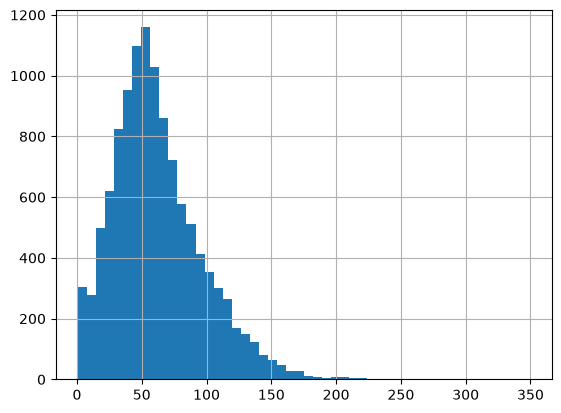

In [17]:
print(data_clean['turns'].describe())
data_clean['turns'].hist(bins = 50)
plt.show()

In [ ]:
# split increment_code (e.g. "180+180") into base time and increment
split_time = data_clean['increment_code'].str.split('+', expand = True)
data_clean['base_time'] = split_time[0].astype(int)
data_clean['increment_time_seconds'] = split_time[1].astype(int)

In [19]:
# calculate estimated_play_time as  2*base_time + turns*(increment_time_seconds/60)
data_clean['estimated_play_time'] = 2*data_clean['base_time'] + data_clean['turns']*(data_clean['increment_time_seconds']/60)
data_clean[['increment_code', 'turns', 'play_time', 'estimated_play_time']].sample(10)

,increment_code,turns,play_time,estimated_play_time
13158,10+0,63,10.163917,20.000000
7730,10+0,65,166.666667,20.000000
13852,10+0,103,12.742950,20.000000
6514,20+5,50,166.666667,44.166667
11452,10+0,15,2.503867,20.000000
18659,10+10,65,23.896567,30.833333
18494,10+10,120,33.024000,40.000000
17837,10+0,25,5.238250,20.000000
15018,16+8,37,7.794367,36.933333
15249,10+0,39,3.023633,20.000000


In [20]:
inconsistent_time = (data_clean['play_time'] > data_clean['estimated_play_time']).sum()
print(f'Matches with implausible play_time: {inconsistent_time}')
print(f'Percentage of dataset: {inconsistent_time / len(data_clean) * 100:.2f}%')

Matches with implausible play_time: 965
Percentage of dataset: 8.38%


In [21]:
# how much do these matches exceed the theoretical maximum?
inconsistent_matches = data_clean[data_clean['play_time'] > data_clean['estimated_play_time']].copy()
inconsistent_matches['excess_ratio'] = inconsistent_matches['play_time'] / inconsistent_matches['estimated_play_time']
print(inconsistent_matches['excess_ratio'].describe())

count    965.000000
mean       5.179206
std        4.344617
min        1.000075
25%        1.736111
50%        4.385965
75%        8.333333
max       69.895156
Name: excess_ratio, dtype: float64


In [22]:
# allow a 50% tolerance margin over the theoretical maximum before flagging as implausible
tolerance = 1.5
implausible_time = data_clean['play_time'] > (data_clean['estimated_play_time'] * tolerance)

print(f'Matches with implausible play_time (tolerance : {tolerance}x): {implausible_time.sum()}')
print(f'Percentage of dataset: {implausible_time.sum() / len(data_clean) * 100:.2f}%')

Matches with implausible play_time (tolerance : 1.5x): 731
Percentage of dataset: 6.35%


In [23]:
# check how the count of flagged matches changes as tolerance increases
for t in [1.2, 1.5, 2.0, 2.5, 3.0, 4.0, 5.0]:
    count = (data_clean['play_time'] > (data_clean['estimated_play_time'] * t)).sum()
    pct = count / len(data_clean) * 100
    print(f'Tolerance {t}x: {count} matches ({pct:.2f}%)')

Tolerance 1.2x: 763 matches (6.63%)
Tolerance 1.5x: 731 matches (6.35%)
Tolerance 2.0x: 707 matches (6.14%)
Tolerance 2.5x: 684 matches (5.94%)
Tolerance 3.0x: 644 matches (5.60%)
Tolerance 4.0x: 539 matches (4.68%)
Tolerance 5.0x: 452 matches (3.93%)


In [24]:
# apply a 2x tolerance threshold on theoretical maximum play_time, 
# balancing physical plausibility (connection lag) against not discarding legitimate slower-paced matches
tolerance = 2.0
data_final = data_clean[data_clean['play_time'] <= data_clean['estimated_play_time'] * tolerance].copy()

print(f'Observations before time consistency cleaning: {len(data_clean)}')
print(f'Observations after time consistency cleaning: {len(data_final)}')
print(f'Percentage removed: {(len(data_clean) - len(data_final)) / len(data_clean) * 100:.2f}%')

Observations before time consistency cleaning: 11510
Observations after time consistency cleaning: 10803
Percentage removed: 6.14%


In [25]:
# distribution rating vs winner after cleaning
print(data_final['winner'].value_counts())
print(f'Target value distribution:')
print(f'white winner target rate : {(data_final['winner'] == 'white').sum()/data_final['winner'].count()*100:.2f}%')
print(f'black winner target rate : {(data_final['winner'] == 'black').sum()/data_final['winner'].count()*100:.2f}%')
print(f'draw  target rate : {(data_final['winner'] == 'draw').sum()/data_final['winner'].count()*100:.2f}%')

winner
white    5424
black    4841
draw      538
Name: count, dtype: int64
Target value distribution:
white winner target rate : 50.21%
black winner target rate : 44.81%
draw  target rate : 4.98%


In [26]:
data_final.head(1)

,id,rated,start_time,end_time,turns,victory_status,winner,increment_code,white_id,white_rating,black_id,black_rating,moves,opening_eco,opening_name,opening_moves,play_time,base_time,increment_time_seconds,estimated_play_time
43,oqoT4DLS,False,1.499610e+12,1.499620e+12,66,resign,white,40+40,rajuppi,2443,shivangithegenius,978,e4 c5 Nf3 d6 d4 cxd4 Nxd4 Nf6 Nc3 g6 Be3 Bg7 f...,B76,Sicilian Defense: Dragon Variation | Yugoslav...,17,166.666667,40,40,124.0


Data Visualization

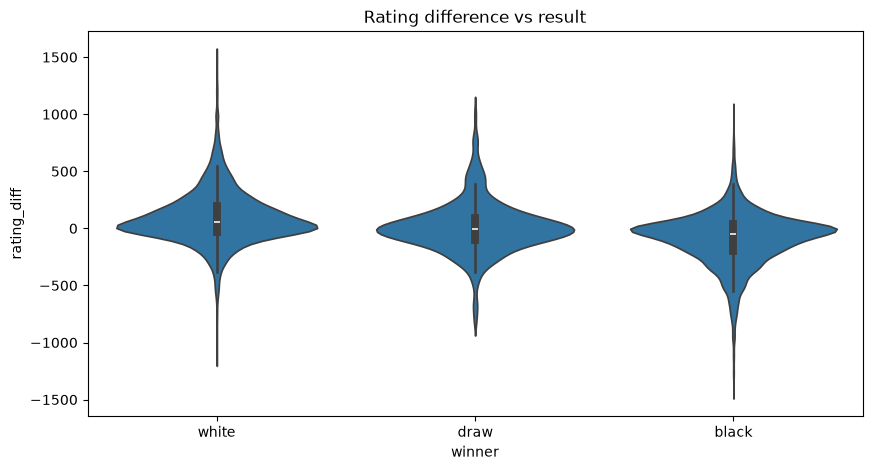

In [27]:
# Rating vs result
data_final['rating_diff'] = data_final['white_rating'] - data_final['black_rating']
plt.figure(figsize = (10,5))
sns.violinplot(data = data_final, x = 'winner', y = 'rating_diff')
plt.title('Rating difference vs result')
plt.savefig('images/violinplot_diff_rate_result.png', dpi = 300, bbox_inches = 'tight')
plt.show()

# the three distribution slightly overlapped, and long tails in wthite and black distribution
# this imply to not take for granted the favourite victory

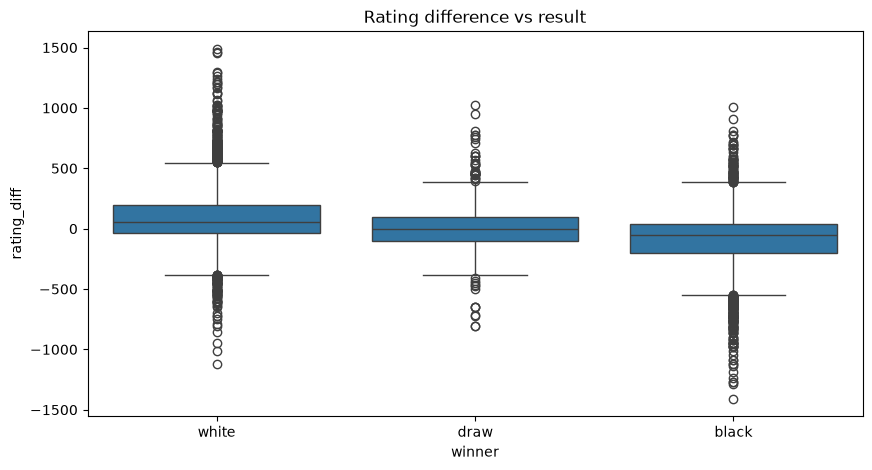

In [28]:
plt.figure(figsize = (10,5))
sns.boxplot(data = data_final, x = 'winner', y = 'rating_diff')
plt.title('Rating difference vs result')
plt.savefig('images/ boxplot_diff_rate_result.png', dpi = 300, bbox_inches = 'tight')
plt.show()


In [29]:
# winning rate of the highest rated player (the favorite)
data_final['favorite_won'] = (
    ((data_final['rating_diff'] > 0) & (data_final['winner'] == 'white')) | 
    ((data_final['rating_diff'] < 0) & (data_final['winner'] == 'black'))
)

# exclude draw and  cases with rating_diff = 0, for a clean rate
decisive = data_final[(data_final['rating_diff'] != 0) & (data_final['winner'] != 'draw')]
# mean calculated considering only match with a victory
print(f'favorite player winning rate : {decisive['favorite_won'].mean()*100:.2f}%')

# As the violin plot shows, the favorite winning rate ins't so high as tought

favorite player winning rate : 65.59%


In [30]:
# opening move vs results
# since opening_moves has many unique values, I focus on its first n
n = 15
print(f'Unique opening moves values : {len(data_final['opening_eco'].unique())}') # .sort_index()
# how much dataset they cover
print(f'Coverage of the first {n} : {data_final['opening_eco'].value_counts(normalize = True).head(n).sum()*100:.2f}%')

Unique opening moves values : 339
Coverage of the first 15 : 43.25%


In [31]:
# subset with the first highest n occurance opening moves
top_values = data_final['opening_eco'].value_counts().head(n).index
subset = data_final[data_final['opening_eco'].isin(top_values)]
subset.shape

(4672, 22)

Text(0.5, 1.0, 'Opening move rate')

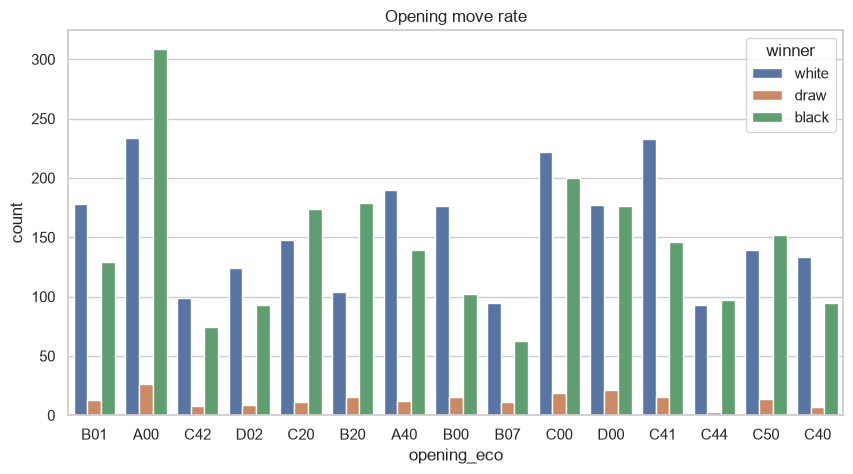

In [32]:
# count plot quick overview
sns.set_theme(style="whitegrid")
plt.figure(figsize = (10,5))
sns.countplot(data = subset, x = 'opening_eco', hue = 'winner')
plt.title('Opening move rate')

In [33]:
# win rate considering opening move
win_rate_by_opening_move= subset.groupby('opening_eco')['winner'].value_counts(normalize = True).unstack()
print(win_rate_by_opening_move.sample())

winner          black      draw     white
opening_eco                              
A00          0.543058  0.045694  0.411248


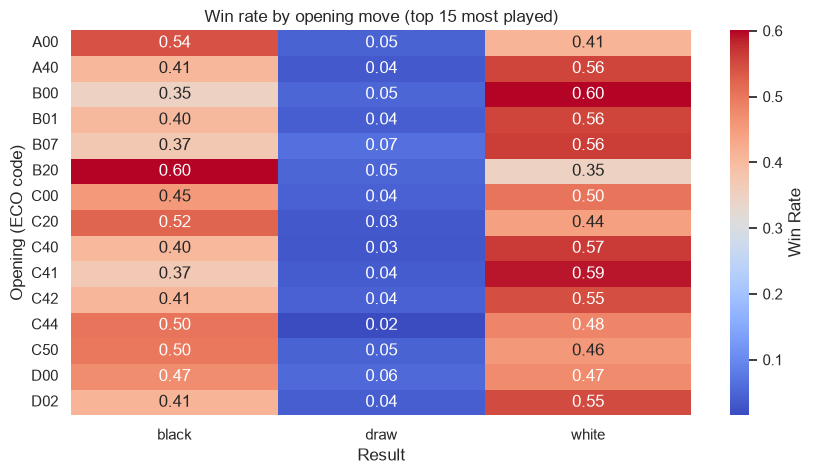

In [34]:
# occurances heat map
plt.figure(figsize = (10,5))
sns.heatmap(win_rate_by_opening_move, annot = True, cmap = 'coolwarm', fmt = '.2f', cbar_kws = {'label' : 'Win Rate'})
plt.title(f'Win rate by opening move (top {n} most played)')
plt.xlabel('Result')
plt.ylabel('Opening (ECO code)')
plt.savefig('images/win_rate_by_opening_move.png', dpi = 300, bbox_inches = 'tight')
plt.show()

# the heatmap shows that some opening move might be connected to black/with vicotry.
# However, since there are very few draw cases, nothing can be deducted for that class

winner     black      draw     white
rated                               
False   0.446860  0.065700  0.487440
True    0.448414  0.046032  0.505554


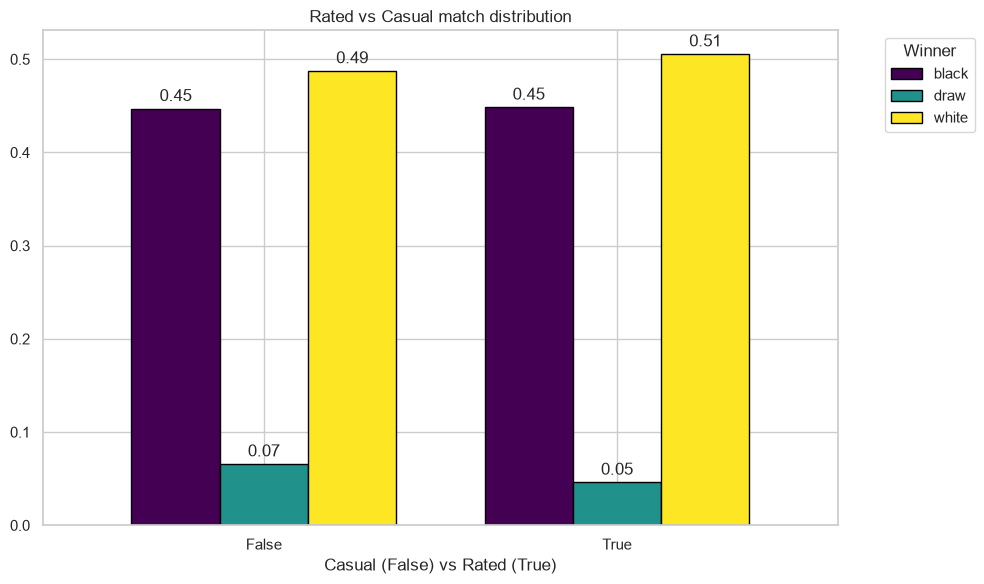

In [35]:
# Rated vs Casual mathces distribution
rate_rated = data_final.groupby('rated')['winner'].value_counts(normalize = True).unstack()
print(rate_rated)

ax = rate_rated.plot(kind = 'bar', figsize = (10,6), width = .75, edgecolor  = 'black', cmap = 'viridis')
plt.title('Rated vs Casual match distribution')
plt.xlabel('Casual (False) vs Rated (True)')
plt.xticks(rotation=0)
plt.legend(title = "Winner", bbox_to_anchor=(1.05, 1), loc='upper left')

for container in ax.containers:
    ax.bar_label(container, fmt='%.2f', padding=3)

plt.tight_layout()
plt.savefig('images/rated_vs_casual_by_result.png', dpi = 300, bbox_inches = 'tight')
plt.show()
# this plot suggest no different distribution of the result considering rated or casual matches

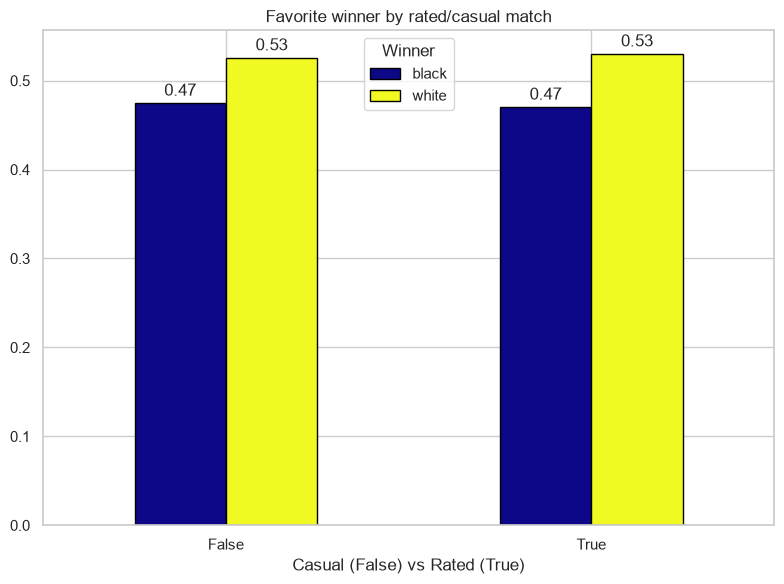

In [36]:
# percentage favorite win concerning rated/casual match
decisive_vs_rated = decisive.groupby('rated')['winner'].value_counts(normalize = True).unstack()

ax = decisive_vs_rated.plot(kind = 'bar', figsize = (8,6), edgecolor = 'black', cmap = 'plasma')
plt.title('Favorite winner by rated/casual match')
plt.xlabel('Casual (False) vs Rated (True)')
plt.xticks(rotation = 0)
plt.legend(title = "Winner", loc='upper center')
#plt.grid(axis='y', linestyle='--', alpha=0.5)

# plot percentage on each bar
for container in ax.containers:
    ax.bar_label(container, fmt='%.2f', padding=3)

plt.tight_layout()
plt.savefig('images/rated_vs_casual_by_favorite.png', dpi = 300, bbox_inches = 'tight')
plt.show()

# the plot suggests no diffence between favorite winner considering rated or casual matches

In [37]:
# calculate percentage of favorite won considering rated == True/False
print(f"Favorite win rate in rated matches : {decisive[decisive['rated'] == True]['favorite_won'].mean()*100:.2f}%")
print(f"Favorite win rate in casual matches : {decisive[decisive['rated'] == False]['favorite_won'].mean()*100:.2f}%")
# As depicted by the plot, the match type (rated or not) seems to not influeced th the favorite rate

Favorite win rate in rated matches : 65.17%
Favorite win rate in casual matches : 67.46%


In [38]:
# Time vs draw
#data_final.drop(columns = ['is_decisive'])
data_final['is_draw'] = data['winner'] == 'draw'

In [39]:
print(data_final['base_time'].unique())
print(data_final['base_time'].value_counts().sort_index())
# ther are 33 base_time values, including 0

[ 40   5 180  60  10  30  20  90  45   0   6  19   8  12  15   9  25  29
   1   3 120   2   7  11   4  35  17  18  14 150  16  13  21]
base_time
0        32
1        19
2        26
3        36
4        38
5       921
6        73
7       386
8       522
9       147
10     5159
11       44
12      135
13       36
14       33
15     1685
16       27
17       16
18       10
19       14
20      443
21        1
25      202
29        2
30      441
35        8
40       27
45      131
60       64
90       10
120      13
150       9
180      93
Name: count, dtype: int64


In [40]:
# check 0 as base time
data_final[data_final['base_time'] == 0][['increment_code', 'increment_time_seconds', 'turns']].head(10)
# incremnt_time showed is plausible with a O base time match

,increment_code,increment_time_seconds,turns
9084,0+180,180,71
9608,0+16,16,2
9609,0+16,16,4
9610,0+16,16,2
9611,0+16,16,2
9612,0+16,16,37
9613,0+16,16,39
9614,0+16,16,23
9615,0+16,16,33
9616,0+16,16,2


In [41]:
# due to the high number of value in base_time, matches can be categorized taking into account Lichness classification:
# Bullet: < 3 minutes
# Blitz: 3-10 minutes
# Rapid: 10-30 minutes
# Classical: 30+ minutes
# Moreover, it must be taken into account matche with base_time = 0 and increment tiem != 0 (16,180)
# so, estimate time can be calcualte as : base_time + (increment × estimated_turn) (estimated turn roughly euqal to 40)

data_final['estimated_minutes'] = data_final['base_time'] + (data_final['increment_time_seconds'] * 40 / 60)

# estimated_minutes is different from estimated_play_time
# Estimated_play_time is an upper bound for match duration
# estimated_minutes estimats play time

In [ ]:
# categorize estimated game duration in minutes

def categorize_time(time):
    if time < 3:
        return 'Bullet'
    elif time < 10:
        return 'Blitz'
    elif time < 30:
        return 'Rapid'
    else:
        return 'Classical'

data_final['match_category'] = data_final['estimated_minutes'].apply(categorize_time)

match_category
Blitz        4.406780
Classical    8.542247
Rapid        4.610344
Name: is_draw, dtype: float64


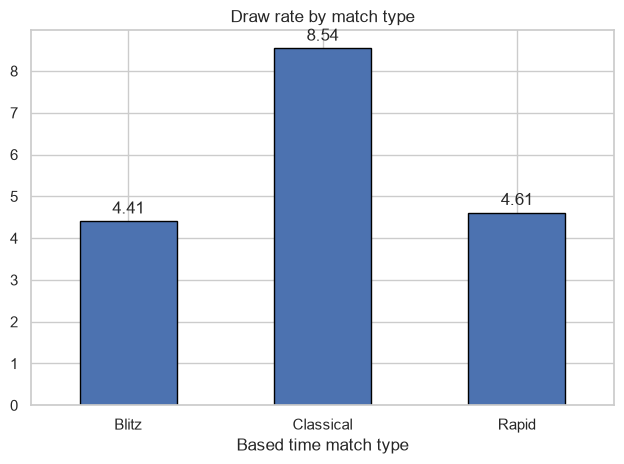

In [43]:
draw_rate_by_time = (data_final.groupby('match_category')['is_draw'].mean())*100#value_counts(normalize = True).unstack()
print(draw_rate_by_time)


ax = draw_rate_by_time.plot(kind = 'bar', edgecolor = 'black')

plt.title('Draw rate by match type')
plt.xlabel('Based time match type')
plt.xticks(rotation = 0)


for container in ax.containers:
    ax.bar_label(container, fmt='%.2f', padding=3)

plt.tight_layout()
plt.savefig('images/draw_rate_by_time.png', dpi = 300, bbox_inches = 'tight')
plt.show()

In [44]:
print(data_final['match_category'].value_counts())
print(data_final['match_category'].unique())
print((data_final['estimated_minutes'] < 3).value_counts())

match_category
Rapid        8546
Blitz        1180
Classical    1077
Name: count, dtype: int64
<StringArray>
['Classical', 'Rapid', 'Blitz']
Length: 3, dtype: str
estimated_minutes
False    10803
Name: count, dtype: int64


In [45]:
# players analysis
# group with player name (between with and black) and ralet it to the number of played matches
data_final[['black_id','white_id']].count()

black_id    10803
white_id    10803
dtype: int64

In [46]:
#players_id = pd.concat([data_final['white_id'], data_final['black_id']]).drop_duplicates().reset_index(drop = True)

In [47]:
# for each players, how many matches in white and black 
# count matches played as white and as black for each player, vectorized
white_counts = data_final['white_id'].value_counts()
black_counts = data_final['black_id'].value_counts()

players = pd.DataFrame({
    'as_white': white_counts,
    'as_black': black_counts
}).fillna(0).astype(int)

players['total_matches'] = players['as_white'] + players['as_black']
players = players.reset_index().rename(columns={'index': 'player_id'})

players.head()

,player_id,as_white,as_black,total_matches
0,--jim--,1,0,1
1,-0olo0-,0,1,1
2,-l-_jedi_knight_-l-,6,6,12
3,-mati-,1,0,1
4,-pavel-,1,0,1


count    8828.000000
mean        2.447440
std         5.844542
min         1.000000
25%         1.000000
50%         1.000000
75%         2.000000
max       120.000000
Name: total_matches, dtype: float64


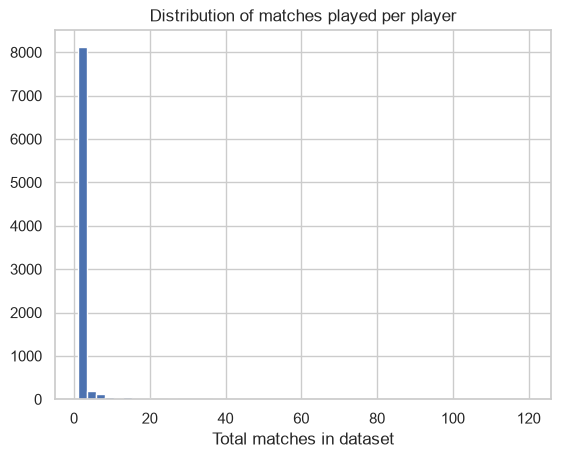

Players with only 1 match: 6574 (74.5%)
Players with 5+ matches: 590 (6.7%)


In [48]:
print(players['total_matches'].describe())
players['total_matches'].hist(bins=50)
plt.title('Distribution of matches played per player')
plt.xlabel('Total matches in dataset')
plt.show()
print(f"Players with only 1 match: {(players['total_matches'] == 1).sum()} ({(players['total_matches'] == 1).mean()*100:.1f}%)")
print(f"Players with 5+ matches: {(players['total_matches'] >= 5).sum()} ({(players['total_matches'] >= 5).mean()*100:.1f}%)")

In [49]:
# favorite won - player experience relation

data_final = data_final.merge(players[['player_id', 'total_matches']], left_on='white_id', right_on='player_id', how='left')
data_final = data_final.rename(columns={'total_matches': 'white_total_matches'}).drop(columns='player_id')

data_final = data_final.merge(players[['player_id', 'total_matches']], left_on='black_id', right_on='player_id', how='left')
data_final = data_final.rename(columns={'total_matches': 'black_total_matches'}).drop(columns='player_id')

data_final.head(2)

,id,rated,start_time,end_time,turns,victory_status,winner,increment_code,white_id,white_rating,...,base_time,increment_time_seconds,estimated_play_time,rating_diff,favorite_won,is_draw,estimated_minutes,match_category,white_total_matches,black_total_matches
0,oqoT4DLS,False,1.499610e+12,1.499620e+12,66,resign,white,40+40,rajuppi,2443,...,40,40,124.000000,1465,True,False,66.666667,Classical,11,2
1,iq3Kz06t,False,1.498400e+12,1.498410e+12,41,mate,white,40+40,rajuppi,2436,...,40,40,107.333333,1458,True,False,66.666667,Classical,11,2


In [50]:
# threshold match for low experience player
# Since 75% of player has played 1 matche at least
threshold = 1
data_final['low_experience_player'] = (data_final['white_total_matches'] <= threshold) | (data_final['black_total_matches'] <= threshold)

# calculate decisive again to include the new feature
decisive = data_final[(data_final['rating_diff'] != 0) & (data_final['winner'] != 'draw')]

favorite_rate_by_experience = decisive.groupby('low_experience_player')['favorite_won'].mean() * 100
print(favorite_rate_by_experience)

# ther isn't a so evident difference between the two distribution, hence low number of played matches doesn't imply low experience

low_experience_player
False    66.286847
True     65.134474
Name: favorite_won, dtype: float64


# 2. Three classes prediction problem

## 2.1 Feature Engineering/Preprocessing Pipeline

In [51]:
data_final.columns

Index(['id', 'rated', 'start_time', 'end_time', 'turns', 'victory_status',
       'winner', 'increment_code', 'white_id', 'white_rating', 'black_id',
       'black_rating', 'moves', 'opening_eco', 'opening_name', 'opening_moves',
       'play_time', 'base_time', 'increment_time_seconds',
       'estimated_play_time', 'rating_diff', 'favorite_won', 'is_draw',
       'estimated_minutes', 'match_category', 'white_total_matches',
       'black_total_matches', 'low_experience_player'],
      dtype='str')

In [52]:
# select columns to hold
columns_to_keep = ['rated', 'winner', 'base_time', 'increment_time_seconds', 
                    'match_category', 'white_rating', 'black_rating', 'rating_diff', 
                    'opening_eco', 'opening_moves']

data_model = data_final[columns_to_keep].copy()
print(data_model.shape)
print(data_model.head())

(10803, 10)
   rated winner  base_time  increment_time_seconds match_category  \
0  False  white         40                      40      Classical   
1  False  white         40                      40      Classical   
2  False  white          5                      60      Classical   
3  False   draw        180                     180      Classical   
4   True  white         60                       0      Classical   

   white_rating  black_rating  rating_diff opening_eco  opening_moves  
0          2443           978         1465         B76             17  
1          2436           978         1458         B01              4  
2          1760          1542          218         A08              4  
3          1500          1500            0         A00              1  
4          1416          1216          200         C42              5  


In [53]:
# Split target from dataset
y = data_model['winner']
X = data_model.drop(columns = ['winner'])

# train test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, stratify = y, random_state = 42)

# make sure that X_train and X_test are indipendent copies befor modifying them
X_train = X_train.copy()
X_test = X_test.copy()

In [54]:
# facing the high cardinality of opening_eco
num_of_openings = 20
print(f'Unique opening moves values : {len(data_model['opening_eco'].unique())}') # .sort_index()
# how much dataset they cover
print(f'Coverage of the first {num_of_openings} : {data_model['opening_eco'].value_counts(normalize = True).head(num_of_openings).sum()*100:.2f}%')

#top_openings = data_model['opening_eco'].value_counts(normalize = True).head(num_of_openings).index -> this way will cause data lekeage
# identify top 20 openings ONLY from training data
top_openings = X_train['opening_eco'].value_counts(normalize = True).head(num_of_openings). index
print(f'Unique opening moves values in train set : {len(X_train['opening_eco'].unique())}') # .sort_index()
# how much dataset they cover
print(f'Coverage of the first in train data {num_of_openings} : {X_train['opening_eco'].value_counts(normalize = True).head(num_of_openings).sum()*100:.2f}%')

print(top_openings)

# apply the same grouping to both train and test, using categories learned from train only (20 + 1 values)
# X_train['opening_eco_grouped'] = X_train['opening_eco'].apply(lambda x: x if x in top_openings else 'Other')
# X_test['opening_eco_grouped'] = X_test['opening_eco'].apply(lambda x: x if x in top_openings else 'Other')
#X_train = X_train.drop(columns = ['opening_eco'])
#X_test = X_test.drop(columns = ['opening_eco'])

Unique opening moves values : 339
Coverage of the first 20 : 50.55%
Unique opening moves values in train set : 326
Coverage of the first in train data 20 : 50.53%
Index(['A00', 'C00', 'C41', 'D00', 'C20', 'A40', 'B01', 'C50', 'B00', 'B20',
       'D02', 'C40', 'C44', 'C42', 'B07', 'C55', 'C45', 'C02', 'A04', 'A45'],
      dtype='str', name='opening_eco')


In [55]:
X_train.columns.to_list()

['rated',
 'base_time',
 'increment_time_seconds',
 'match_category',
 'white_rating',
 'black_rating',
 'rating_diff',
 'opening_eco',
 'opening_moves']

In [56]:
num_col = ['base_time', 'increment_time_seconds', 'white_rating', 'black_rating', 'rating_diff', 'opening_moves']
cat_col = ['rated', 'match_category', 'opening_eco']

num_pipeline = Pipeline(steps = [('scaler', StandardScaler())])

# as seen previously opening_eco has 339 unique categories: a plain one-hot encoding would create hundreds of sparse columns.
# max_categories=21 keeps the 20 most frequent openings and groups all the others in one 'infrequent' category.
# Alternative considered before: manual grouping (top-20 list computed on train + 'Other' using .apply()),
# more explicit, but the top-20 list would have to be saved and applied separately at inference time.
cat_pipeline = Pipeline(steps = [('encoder', OneHotEncoder( drop = 'if_binary',
                                                            max_categories = 21,
                                                            handle_unknown = 'infrequent_if_exist', 
                                                            sparse_output = False))]) # manage SHAP analysis easly

preprocessor = ColumnTransformer(transformers = [('num', num_pipeline, num_col), ('cat', cat_pipeline, cat_col)])

# encoding label
le = LabelEncoder()
y_train_enc = le.fit_transform(y_train)
y_test_enc = le.transform(y_test)
class_names = le.classes_
print(class_names)   # order of classes = order of columns in predict_proba -> 1. black, 2. draw, 3. white

# transformer check
preprocessor.fit(X_train)
print(preprocessor.get_feature_names_out())

['black' 'draw' 'white']
['num__base_time' 'num__increment_time_seconds' 'num__white_rating'
 'num__black_rating' 'num__rating_diff' 'num__opening_moves'
 'cat__rated_True' 'cat__match_category_Blitz'
 'cat__match_category_Classical' 'cat__match_category_Rapid'
 'cat__opening_eco_A00' 'cat__opening_eco_A04' 'cat__opening_eco_A40'
 'cat__opening_eco_A45' 'cat__opening_eco_B00' 'cat__opening_eco_B01'
 'cat__opening_eco_B07' 'cat__opening_eco_B20' 'cat__opening_eco_C00'
 'cat__opening_eco_C02' 'cat__opening_eco_C20' 'cat__opening_eco_C40'
 'cat__opening_eco_C41' 'cat__opening_eco_C42' 'cat__opening_eco_C44'
 'cat__opening_eco_C45' 'cat__opening_eco_C50' 'cat__opening_eco_C55'
 'cat__opening_eco_D00' 'cat__opening_eco_D02'
 'cat__opening_eco_infrequent_sklearn']


##### Evaluation metrics: 
- *Logloss* --> probability evaluation
- *F1* (Macro) --> classification evaluation
- *ConfusionMatrix* --> model evaluation

In [57]:
# define utility function for evaluating metrics

def evaluate_model(model_name, y_true, y_proba, class_names):
    '''Utility function for gauging model performances'''

    # take out prediction from probability
    y_pred = np.argmax(y_proba, axis = 1)

    print(f'====== {model_name} performaces ======\n')

    # one F1 column per class (e.g. F1_black, F1_draw, F1_white) so results fit in a DataFrame
    f1_ = f1_score(y_true, y_pred, average = None)
    f1_per_class = {f'F1_{name}' : f1 for name, f1 in zip(class_names,f1_)}
    
    # macro treats the three classes equally, weighted hides poor performance on draws
    f1_macro = f1_score(y_true, y_pred, average='macro')
    f1_weighted = f1_score(y_true, y_pred, average='weighted')
    print(f"F1 values : {f1_}")
    print(f"Macro F1 : {f1_macro:.2f}")
    print(f"Weighted F1 : {f1_weighted:.2f}")

    # quality of the probabilities themselves
    logloss = log_loss(y_true, y_proba)
    print(f"Log loss: {logloss:.4f}")

    # per-class detail (precision, recall, F1 for black / draw / white)
    print(classification_report(y_true, y_pred, target_names=class_names, zero_division=0))

    # confusion matrix
    cm = confusion_matrix(y_true, y_pred, normalize = 'true')
    disp = ConfusionMatrixDisplay(confusion_matrix= cm, display_labels= class_names)

    disp.plot(cmap = plt.cm.Blues, values_format = '.2f')

    plt.title(f'{model_name} Confusion Matrix')
    plt.savefig(f'images/confusion_matrix_{model_name}.png', dpi=300, bbox_inches='tight')
    plt.show()

    return {'Model': model_name,
            'Accuracy' : accuracy_score(y_true, y_pred),
            **f1_per_class, 
            'F1_macro' : f1_macro, 
            'F1_weighted' : f1_weighted, 
            'Log_Loss' : logloss}

## 2.2 Classification Moddel (Pre-match percentage classification)

### Dummy Classifier

====== Dummy performaces ======

F1 values : [0.        0.        0.6685151]
Macro F1 : 0.22
Weighted F1 : 0.34
Log loss: 0.8554
              precision    recall  f1-score   support

       black       0.00      0.00      0.00       968
        draw       0.00      0.00      0.00       108
       white       0.50      1.00      0.67      1085

    accuracy                           0.50      2161
   macro avg       0.17      0.33      0.22      2161
weighted avg       0.25      0.50      0.34      2161



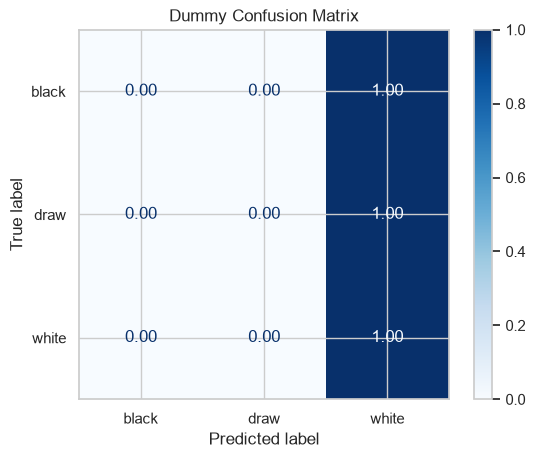

In [58]:
# base line model for LogLoss comparison

dummy = DummyClassifier(strategy = 'prior', random_state = 42)
dummy.fit(X_train, y_train_enc)
dummy_pred = dummy.predict(X_test)
dummy_proba = dummy.predict_proba(X_test)

#print(f'Dummy model performances : \n {classification_report(y_test_enc, dummy_pred, target_names = le.classes_, zero_division = 0)} \n')
#print(f'Dummy model LogLoss : {log_loss(y_test_enc, dummy_proba)}')

results = []
results.append(evaluate_model('Dummy', y_test_enc, dummy_proba, class_names))

### Logistic Regression

c:\Users\vyncy\OneDrive\Desktop\MLE_DataMaster\Modulo_Algoritmi_Machine_learning\venv_p12\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)


====== Logistic_Regression performaces ======

F1 values : [0.59042553 0.         0.66752356]
Macro F1 : 0.42
Weighted F1 : 0.60
Log loss: 0.7871
              precision    recall  f1-score   support

       black       0.61      0.57      0.59       968
        draw       0.00      0.00      0.00       108
       white       0.62      0.72      0.67      1085

    accuracy                           0.62      2161
   macro avg       0.41      0.43      0.42      2161
weighted avg       0.59      0.62      0.60      2161



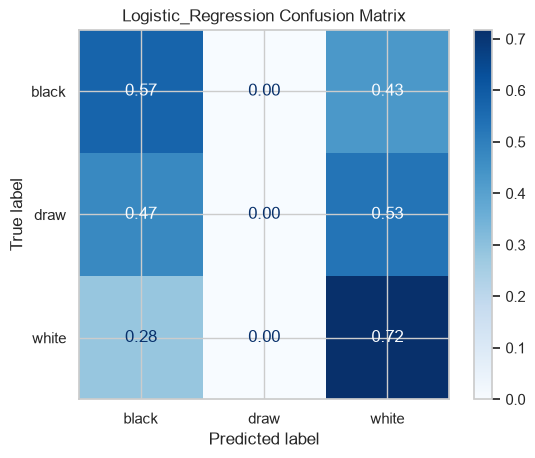

In [59]:
# define model pipeline
lr_pipeline = Pipeline(steps = [('preprocessing', preprocessor), 
                                ('logistic_regression', LogisticRegression(max_iter = 1000, random_state = 42))])

# fit pipeline
lr_pipeline.fit(X_train, y_train_enc)

# extract probability
proba_lr = lr_pipeline.predict_proba(X_test)

# model evaluation
results.append(evaluate_model('Logistic_Regression', y_test_enc, proba_lr, class_names))

In [60]:
# check the predicted probability the model assigns to 'draw', even when it never wins the argmax
draw_col = list(le.classes_).index('draw')
#print(proba_lr[:, draw_col].describe() if hasattr(proba_lr[:, draw_col], 'describe') else pd.Series(proba_lr[:, draw_col]).describe())
pd.Series(proba_lr[:, draw_col]).describe()

count    2161.000000
mean        0.048915
std         0.023967
min         0.007157
25%         0.033437
50%         0.045022
75%         0.058664
max         0.249896
dtype: float64

c:\Users\vyncy\OneDrive\Desktop\MLE_DataMaster\Modulo_Algoritmi_Machine_learning\venv_p12\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)


====== Logistic_Regression_balanced performaces ======

F1 values : [0.56179775 0.09693053 0.5824233 ]
Macro F1 : 0.41
Weighted F1 : 0.55
Log loss: 1.0154
              precision    recall  f1-score   support

       black       0.62      0.52      0.56       968
        draw       0.06      0.28      0.10       108
       white       0.67      0.52      0.58      1085

    accuracy                           0.50      2161
   macro avg       0.45      0.44      0.41      2161
weighted avg       0.61      0.50      0.55      2161



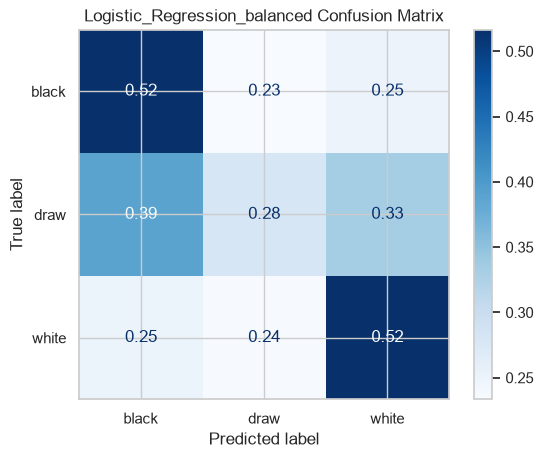

In [61]:
# Logitic Regression Balanced

# define model pipeline
lr_balanced_pipeline = Pipeline(steps = [('preprocessing', preprocessor), 
                                ('logistic_regression', LogisticRegression(max_iter = 1000,
                                                                           class_weight = 'balanced',
                                                                           random_state = 42))])

# fit pipeline
lr_balanced_pipeline.fit(X_train, y_train_enc)

# extract probability
proba_lr_balanced = lr_balanced_pipeline.predict_proba(X_test)

# model evaluation
results.append(evaluate_model('Logistic_Regression_balanced', y_test_enc, proba_lr_balanced, class_names))

### Random Forest

c:\Users\vyncy\OneDrive\Desktop\MLE_DataMaster\Modulo_Algoritmi_Machine_learning\venv_p12\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)


====== Random Forest performaces ======

F1 values : [0.59213251 0.10852713 0.64750111]
Macro F1 : 0.45
Weighted F1 : 0.60
Log loss: 0.8165
              precision    recall  f1-score   support

       black       0.59      0.59      0.59       968
        draw       0.33      0.06      0.11       108
       white       0.62      0.67      0.65      1085

    accuracy                           0.61      2161
   macro avg       0.52      0.44      0.45      2161
weighted avg       0.59      0.61      0.60      2161



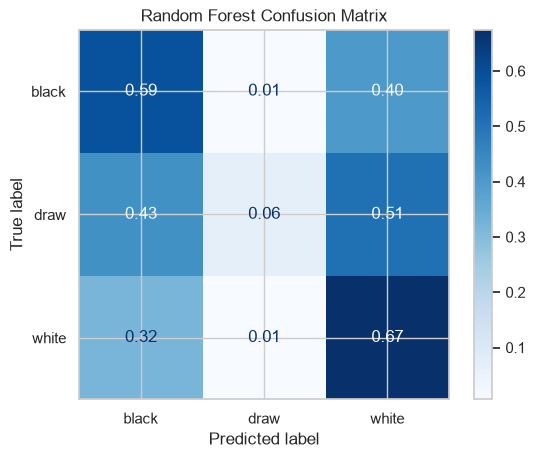

Random Forest train set accuracy : 0.999


c:\Users\vyncy\OneDrive\Desktop\MLE_DataMaster\Modulo_Algoritmi_Machine_learning\venv_p12\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)


Random Forest test set accuracy : 0.607


In [62]:
# define model pipeline
rf_pipeline = Pipeline(steps = [('preprocessing', preprocessor), 
                                ('random_forest', RandomForestClassifier(n_estimators = 1000, 
                                                                         random_state = 42))])

# fit pipeline
rf_pipeline.fit(X_train, y_train_enc)

# extract probability
proba_rf = rf_pipeline.predict_proba(X_test)

# model evaluation
results.append(evaluate_model('Random Forest', y_test_enc, proba_rf, class_names))

# check model overfitting
print(f'Random Forest train set accuracy : {rf_pipeline.score(X_train, y_train_enc):.3f}')
print(f'Random Forest test set accuracy : {rf_pipeline.score(X_test, y_test_enc):.3f}')
# test set accuracy << train set accuravy --> model overfits

In [63]:
# Tuning Random Forest hyper-parameters

# define params
param_grid = {'random_forest__n_estimators' : [100, 200, 300], 
              'random_forest__max_depth' : [5, 10, 15, 20], 
              'random_forest__min_samples_leaf' : [1 , 5, 10]
              }

# define grid search object
grid_search_rf = GridSearchCV(estimator = rf_pipeline, 
                              param_grid = param_grid, 
                              cv = 5, 
                              scoring = 'neg_log_loss', 
                              n_jobs = 1)
                              
# fit grid search
grid_search_rf.fit(X_train, y_train_enc)

print(f'Best parameter : {grid_search_rf.best_params_}')
print(f'Best cross-validated Log-Loss : {-grid_search_rf.best_score_:.4f}')

c:\Users\vyncy\OneDrive\Desktop\MLE_DataMaster\Modulo_Algoritmi_Machine_learning\venv_p12\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)
c:\Users\vyncy\OneDrive\Desktop\MLE_DataMaster\Modulo_Algoritmi_Machine_learning\venv_p12\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)
c:\Users\vyncy\OneDrive\Desktop\MLE_DataMaster\Modulo_Algoritmi_Machine_learning\venv_p12\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)
c:\Users\vyncy\OneDrive\Desktop\ML

Best parameter : {'random_forest__max_depth': 15, 'random_forest__min_samples_leaf': 1, 'random_forest__n_estimators': 300}
Best cross-validated Log-Loss : 0.7650


c:\Users\vyncy\OneDrive\Desktop\MLE_DataMaster\Modulo_Algoritmi_Machine_learning\venv_p12\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)


Random Forest tuned train set accuracy : 0.817
Random Forest tuned test set accuracy : 0.625
====== Random Forest Tuned performaces ======

F1 values : [0.59904408 0.01834862 0.67381974]
Macro F1 : 0.43
Weighted F1 : 0.61
Log loss: 0.7732
              precision    recall  f1-score   support

       black       0.62      0.58      0.60       968
        draw       1.00      0.01      0.02       108
       white       0.63      0.72      0.67      1085

    accuracy                           0.62      2161
   macro avg       0.75      0.44      0.43      2161
weighted avg       0.64      0.62      0.61      2161



c:\Users\vyncy\OneDrive\Desktop\MLE_DataMaster\Modulo_Algoritmi_Machine_learning\venv_p12\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)


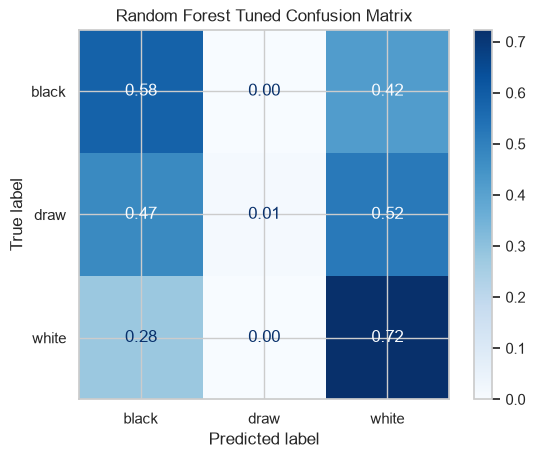

In [64]:
# Random Forest tuned
rf_tuned = grid_search_rf.best_estimator_

proba_rf_tuned = rf_tuned.predict_proba(X_test)

# check model overfitting
print(f'Random Forest tuned train set accuracy : {rf_tuned.score(X_train, y_train_enc):.3f}')
print(f'Random Forest tuned test set accuracy : {rf_tuned.score(X_test, y_test_enc):.3f}')
# test accuracy < train accuracy but Log-Loss has decreased

# model evaluation
results.append(evaluate_model('Random Forest Tuned', y_test_enc, proba_rf_tuned, class_names))

### XGBoost

c:\Users\vyncy\OneDrive\Desktop\MLE_DataMaster\Modulo_Algoritmi_Machine_learning\venv_p12\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)


====== XGB performaces ======

F1 values : [0.57954545 0.08403361 0.64490516]
Macro F1 : 0.44
Weighted F1 : 0.59
Log loss: 0.8388
              precision    recall  f1-score   support

       black       0.58      0.58      0.58       968
        draw       0.45      0.05      0.08       108
       white       0.62      0.67      0.64      1085

    accuracy                           0.60      2161
   macro avg       0.55      0.43      0.44      2161
weighted avg       0.59      0.60      0.59      2161



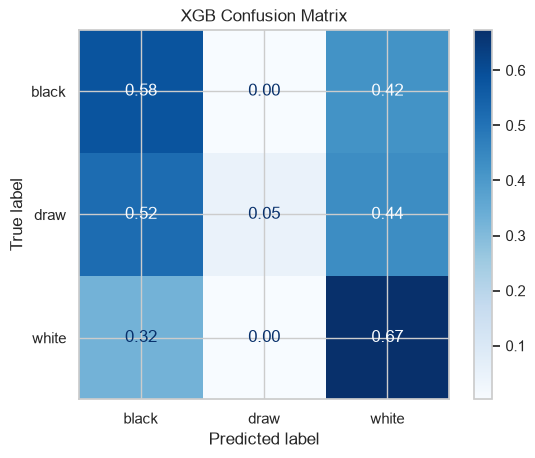

In [65]:
# define model pipeline
xgb_pipeline = Pipeline(steps = [('preprocessing', preprocessor), 
                                ('xgb', XGBClassifier(n_estimators = 100, 
                                                      objective = 'multi:softprob', 
                                                      eval_metric = 'mlogloss', 
                                                      random_state = 42))])

# fit pipeline
xgb_pipeline.fit(X_train, y_train_enc)

# extract probability
proba_xgb = xgb_pipeline.predict_proba(X_test)

# model evaluation
results.append(evaluate_model('XGB', y_test_enc, proba_xgb, class_names))

In [66]:
print(f'Train accuracy: {xgb_pipeline.score(X_train, y_train_enc):.2f}')
print(f'Test accuracy: {xgb_pipeline.score(X_test, y_test_enc):.2f}')

Train accuracy: 0.86
Test accuracy: 0.60


c:\Users\vyncy\OneDrive\Desktop\MLE_DataMaster\Modulo_Algoritmi_Machine_learning\venv_p12\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)


In [67]:
# Tuning XGB hyper-parameters

# define params
param_grid = {'xgb__n_estimators' : [100, 200, 300], 
              'xgb__learning_rate' : [0.01, 0.1, 0.3], 
              'xgb__max_depth' : [3, 6, 9]}

# define grid search object
grid_search_xgb = GridSearchCV(estimator = xgb_pipeline, 
                           param_grid = param_grid, 
                           cv = 5, 
                           scoring = 'neg_log_loss', 
                           n_jobs = -1)
# fit grid search
grid_search_xgb.fit(X_train, y_train_enc)

print(f'Best parameter : {grid_search_xgb.best_params_}')
print(f'Best cross-validated Log-Loss : {-grid_search_xgb.best_score_:.4f}')

Best parameter : {'xgb__learning_rate': 0.01, 'xgb__max_depth': 6, 'xgb__n_estimators': 300}
Best cross-validated Log-Loss : 0.7720


XGB tuned train set accuracy : 0.672
XGB tuned test set accuracy : 0.613
====== XGB Tuned performaces ======

F1 values : [0.58036677 0.01818182 0.66666667]
Macro F1 : 0.42
Weighted F1 : 0.60
Log loss: 0.7844
              precision    recall  f1-score   support

       black       0.61      0.56      0.58       968
        draw       0.50      0.01      0.02       108
       white       0.62      0.72      0.67      1085

    accuracy                           0.61      2161
   macro avg       0.57      0.43      0.42      2161
weighted avg       0.61      0.61      0.60      2161



c:\Users\vyncy\OneDrive\Desktop\MLE_DataMaster\Modulo_Algoritmi_Machine_learning\venv_p12\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)
c:\Users\vyncy\OneDrive\Desktop\MLE_DataMaster\Modulo_Algoritmi_Machine_learning\venv_p12\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)


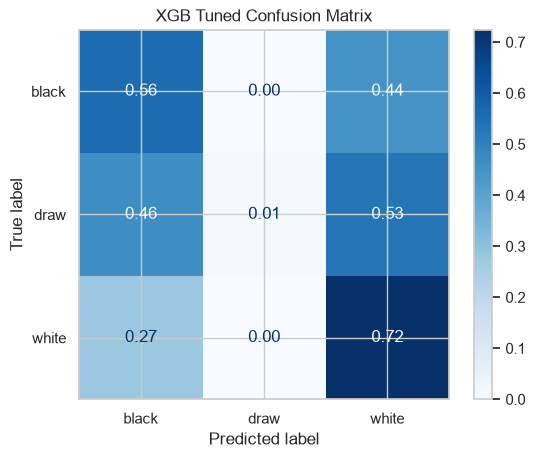

In [68]:
# XGB tuned

xgb_tuned = grid_search_xgb.best_estimator_

proba_xgb_tuned = xgb_tuned.predict_proba(X_test)

# check model overfitting
print(f'XGB tuned train set accuracy : {xgb_tuned.score(X_train, y_train_enc):.3f}')
print(f'XGB tuned test set accuracy : {xgb_tuned.score(X_test, y_test_enc):.3f}')
# test accuracy < train accuracy but Log-Loss has decreased

# model evaluation
results.append(evaluate_model('XGB Tuned', y_test_enc, proba_xgb_tuned, class_names))

In [69]:
# Comparing all the models
Model_Comparison = pd.DataFrame(results)
Model_Comparison

,Model,Accuracy,F1_black,F1_draw,F1_white,F1_macro,F1_weighted,Log_Loss
0,Dummy,0.502082,0.000000,0.000000,0.668515,0.222838,0.335650,0.855410
1,Logistic_Regression,0.617307,0.590426,0.000000,0.667524,0.419316,0.599627,0.787143
2,Logistic_Regression_balanced,0.504396,0.561798,0.096931,0.582423,0.413717,0.548921,1.015422
3,Random Forest,0.606664,0.592133,0.108527,0.647501,0.449387,0.595763,0.816487
4,Random Forest Tuned,0.624711,0.599044,0.018349,0.673820,0.430404,0.607566,0.773172
5,XGB,0.600185,0.579545,0.084034,0.644905,0.436161,0.587597,0.838824
6,XGB Tuned,0.613142,0.580367,0.018182,0.666667,0.421738,0.595600,0.784437


#### Considerations:
- Three Classes Classification model aims to optimize Log-Loss (to display a reliable percentage in the lobby)
- Tuned Random Forest yelds the best Log-Loss value

## 2.3 Calibration Curve

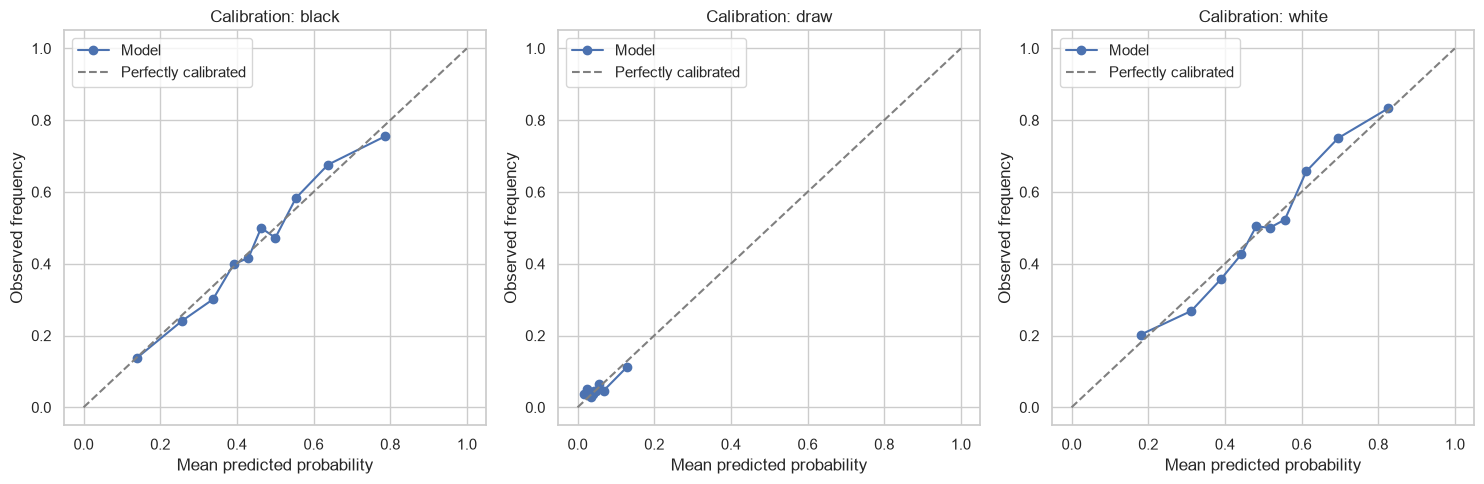

In [70]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for i, class_name in enumerate(le.classes_):
    # one-vs-rest: is the true label this class or not?
    y_true_binary = (y_test_enc == i).astype(int)
    y_prob_class = proba_rf_tuned[:, i]

    # bin predictions and compare mean predicted probability vs observed frequency
    prob_true, prob_pred = calibration_curve(y_true_binary, y_prob_class, n_bins=10, strategy='quantile')

    axes[i].plot(prob_pred, prob_true, marker='o', label='Model')
    axes[i].plot([0, 1], [0, 1], linestyle='--', color='gray', label='Perfectly calibrated')
    axes[i].set_title(f'Calibration: {class_name}')
    axes[i].set_xlabel('Mean predicted probability')
    axes[i].set_ylabel('Observed frequency')
    axes[i].legend()

plt.tight_layout()
plt.savefig('images/calibration_curve_rf.png', dpi = 300, bbox_inches = 'tight')
plt.show()

In [71]:
# brier score
for i, class_name in enumerate(le.classes_):
    y_true_binary = (y_test_enc == i).astype(int)
    brier = brier_score_loss(y_true_binary, proba_rf_tuned[:, i])
    print(f'Brier score ({class_name}): {brier:.4f}')

Brier score (black): 0.2135
Brier score (draw): 0.0467
Brier score (white): 0.2135


In [72]:
# baseline: Brier score if the model always predicted the class base rate
base_rate_draw = y_train_enc[y_train_enc == 1].shape[0] / y_train_enc.shape[0]  # adjust index if needed
baseline_brier = base_rate_draw * (1 - base_rate_draw)
print(f'Baseline Brier score (always predicting base rate): {baseline_brier:.4f}')

Baseline Brier score (always predicting base rate): 0.0473


#### Considerations: 
- RF tuned well-calibrated
- predicted probabilities match observed frequencies
- good discriminative power for black and white classes
- draw class Brier score roughly equal to the baseline that always predicts the average frequency, so it has a very low value


# 3. Binary classification : predict whether the favorite does not win (matchmaking use case)

### 3.1 Feature engineer/Preprocessing pipeline

In [73]:
'''
# winning rate of the highest rated player (the favorite)
data_final['favorite_won'] = (
    ((data_final['rating_diff'] > 0) & (data_final['winner'] == 'white')) | 
    ((data_final['rating_diff'] < 0) & (data_final['winner'] == 'black'))
)

# exclude draw and  cases with rating_diff = 0, for a clean rate
decisive = data_final[(data_final['rating_diff'] != 0) & (data_final['winner'] != 'draw')]
'''
decisive.head()

,id,rated,start_time,end_time,turns,victory_status,winner,increment_code,white_id,white_rating,...,increment_time_seconds,estimated_play_time,rating_diff,favorite_won,is_draw,estimated_minutes,match_category,white_total_matches,black_total_matches,low_experience_player
0,oqoT4DLS,False,1.499610e+12,1.499620e+12,66,resign,white,40+40,rajuppi,2443,...,40,124.000000,1465,True,False,66.666667,Classical,11,2,False
1,iq3Kz06t,False,1.498400e+12,1.498410e+12,41,mate,white,40+40,rajuppi,2436,...,40,107.333333,1458,True,False,66.666667,Classical,11,2,False
2,LEmwK75U,False,1.504050e+12,1.504060e+12,75,resign,white,5+60,niftyleopard,1760,...,60,85.000000,218,True,False,45.000000,Classical,3,1,True
4,2I6CXRvW,True,1.493680e+12,1.493690e+12,63,mate,white,60+0,kurtbusch,1416,...,0,120.000000,200,True,False,60.000000,Classical,1,1,True
5,ivYSNK8V,False,1.489780e+12,1.489800e+12,32,outoftime,black,180+0,willdaplum,1250,...,0,360.000000,-250,True,False,180.000000,Classical,1,1,True


In [74]:
# recompute the expected class balance including draws as "favorite did not win"
# favorite_won -> 1 palyer with higer rank win
# favorite_won -> 0 palyer with lower rank win, or draw case
print(f"Favorite won : {(decisive['favorite_won'].sum() / len(data_final)) * 100:.2f}%")
# matches with no favorite won
print(f"Number of matches with rating_diff = 0 : {(data_final['rating_diff'] == 0).sum()}")
print(f"No favorite matches percentage : {(data_final['rating_diff'] == 0).sum()/len(data_final) * 100:.2f}%")
# this percentage yelds that matches with no difeerence between players rate are less than 1% of the whole dataset --> drop these cases

Favorite won : 61.76%
Number of matches with rating_diff = 0 : 102
No favorite matches percentage : 0.94%


In [75]:
# binary target for matchmaking: did the favorite (higher-rated player) NOT win?
# includes draws as "favorite did not win", since a draw is itself a surprising outcome relative to expectations
# excludes the 102 matches with rating_diff == 0, where "favorite" is not well defined

data_binary = data_final[data_final['rating_diff'] != 0].copy()

# new target 
data_binary['favorite_not_win'] = ~data_binary['favorite_won']
print(f"{data_binary['favorite_not_win'].value_counts(normalize = True)}")

favorite_not_win
False    0.623493
True     0.376507
Name: proportion, dtype: float64


In [76]:
# select columns to hold
columns_to_keep_binary = ['rated', 'base_time', 'increment_time_seconds', 
                    'match_category', 'white_rating', 'black_rating', 'rating_diff', 
                    'opening_eco', 'opening_moves', 'favorite_not_win']

data_binary_model = data_binary[columns_to_keep_binary].copy()
print(data_binary_model.shape)
print(data_binary_model.head())

(10701, 10)
   rated  base_time  increment_time_seconds match_category  white_rating  \
0  False         40                      40      Classical          2443   
1  False         40                      40      Classical          2436   
2  False          5                      60      Classical          1760   
4   True         60                       0      Classical          1416   
5  False        180                       0      Classical          1250   

   black_rating  rating_diff opening_eco  opening_moves  favorite_not_win  
0           978         1465         B76             17             False  
1           978         1458         B01              4             False  
2          1542          218         A08              4             False  
4          1216          200         C42              5             False  
5          1500         -250         C65              6             False  


In [77]:
# Split target from dataset
y_b = data_binary_model['favorite_not_win']
X_b = data_binary_model.drop(columns = ['favorite_not_win'])

# train test split
X_train_b, X_test_b, y_train_b, y_test_b = train_test_split(X_b, y_b, test_size = 0.2, stratify = y_b, random_state = 42)

# make sure that X_train and X_test are indipendent copies befor modifying them
X_train_b = X_train_b.copy()
X_test_b = X_test_b.copy()

In [78]:
# reuse the same preprocessor structure, but fit it fresh on the binary problem's training data
preprocessor_binary = clone(preprocessor)

class_names_binary = ['Favorite won', 'Favorite did not win']  # order must match [False, True] = [0, 1]

# transformer check
preprocessor_binary.fit(X_train_b)
print(preprocessor_binary.get_feature_names_out())

['num__base_time' 'num__increment_time_seconds' 'num__white_rating'
 'num__black_rating' 'num__rating_diff' 'num__opening_moves'
 'cat__rated_True' 'cat__match_category_Blitz'
 'cat__match_category_Classical' 'cat__match_category_Rapid'
 'cat__opening_eco_A00' 'cat__opening_eco_A04' 'cat__opening_eco_A40'
 'cat__opening_eco_A45' 'cat__opening_eco_B00' 'cat__opening_eco_B01'
 'cat__opening_eco_B07' 'cat__opening_eco_B20' 'cat__opening_eco_C00'
 'cat__opening_eco_C02' 'cat__opening_eco_C20' 'cat__opening_eco_C40'
 'cat__opening_eco_C41' 'cat__opening_eco_C42' 'cat__opening_eco_C44'
 'cat__opening_eco_C45' 'cat__opening_eco_C50' 'cat__opening_eco_C55'
 'cat__opening_eco_D00' 'cat__opening_eco_D02'
 'cat__opening_eco_infrequent_sklearn']


## 3.2 Classificaiton Model
### Dummy Model

====== Dummy (binary) performaces ======

F1 values : [0.76812428 0.        ]
Macro F1 : 0.38
Weighted F1 : 0.48
Log loss: 0.6623
                      precision    recall  f1-score   support

        Favorite won       0.62      1.00      0.77      1335
Favorite did not win       0.00      0.00      0.00       806

            accuracy                           0.62      2141
           macro avg       0.31      0.50      0.38      2141
        weighted avg       0.39      0.62      0.48      2141



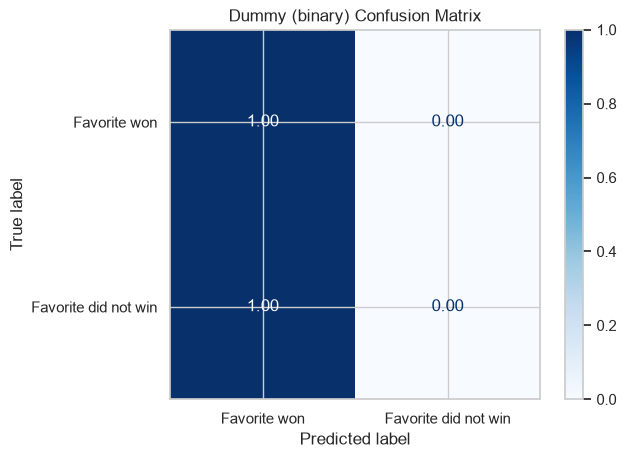

In [79]:
# base line model for LogLoss comparison

dummy_binary = DummyClassifier(strategy = 'prior', random_state = 42)
dummy_binary.fit(X_train_b, y_train_b)
dummy_b_pred = dummy_binary.predict(X_test_b)
dummy_b_proba = dummy_binary.predict_proba(X_test_b)

results_binary = []
results_binary.append(evaluate_model('Dummy (binary)', y_test_b, dummy_b_proba, class_names_binary))

#### Logistic Regression

c:\Users\vyncy\OneDrive\Desktop\MLE_DataMaster\Modulo_Algoritmi_Machine_learning\venv_p12\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)


====== Logistic_Regression (binary) performaces ======

F1 values : [0.76763605 0.00247219]
Macro F1 : 0.39
Weighted F1 : 0.48
Log loss: 0.6670
                      precision    recall  f1-score   support

        Favorite won       0.62      1.00      0.77      1335
Favorite did not win       0.33      0.00      0.00       806

            accuracy                           0.62      2141
           macro avg       0.48      0.50      0.39      2141
        weighted avg       0.51      0.62      0.48      2141



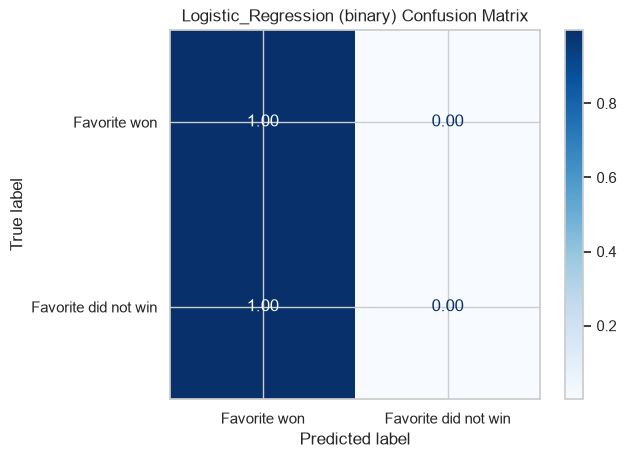

In [80]:
# define model pipeline
lr_b_pipeline = Pipeline(steps = [('preprocessing', preprocessor_binary), 
                                ('logistic_regression', LogisticRegression(max_iter = 1000, random_state = 42))])

# fit pipeline
lr_b_pipeline.fit(X_train_b, y_train_b)

# extract probability
proba_lr_b = lr_b_pipeline.predict_proba(X_test_b)

# model evaluation
results_binary.append(evaluate_model('Logistic_Regression (binary)', y_test_b, proba_lr_b, class_names_binary))

c:\Users\vyncy\OneDrive\Desktop\MLE_DataMaster\Modulo_Algoritmi_Machine_learning\venv_p12\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)


====== Logistic_Regression_balanced (binary) performaces ======

F1 values : [0.53611836 0.46270161]
Macro F1 : 0.50
Weighted F1 : 0.51
Log loss: 0.6985
                      precision    recall  f1-score   support

        Favorite won       0.64      0.46      0.54      1335
Favorite did not win       0.39      0.57      0.46       806

            accuracy                           0.50      2141
           macro avg       0.51      0.52      0.50      2141
        weighted avg       0.55      0.50      0.51      2141



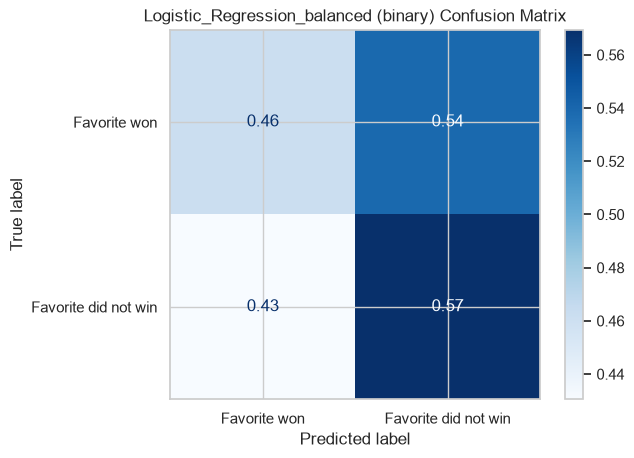

In [81]:
# Logitic Regression Balanced

# define model pipeline
lr_b_balanced_pipeline = Pipeline(steps = [('preprocessing', preprocessor_binary), 
                                ('logistic_regression', LogisticRegression(max_iter = 1000,
                                                                           class_weight = 'balanced',
                                                                           random_state = 42))])

# fit pipeline
lr_b_balanced_pipeline.fit(X_train_b, y_train_b)

# extract probability
proba_lr_b_balanced = lr_b_balanced_pipeline.predict_proba(X_test_b)

# model evaluation
results_binary.append(evaluate_model('Logistic_Regression_balanced (binary)', y_test_b, proba_lr_b_balanced, class_names_binary))

#### Random Forest

c:\Users\vyncy\OneDrive\Desktop\MLE_DataMaster\Modulo_Algoritmi_Machine_learning\venv_p12\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)


====== Random Forest (binary) performaces ======

F1 values : [0.71610024 0.39590942]
Macro F1 : 0.56
Weighted F1 : 0.60
Log loss: 0.6376
                      precision    recall  f1-score   support

        Favorite won       0.66      0.78      0.72      1335
Favorite did not win       0.48      0.34      0.40       806

            accuracy                           0.61      2141
           macro avg       0.57      0.56      0.56      2141
        weighted avg       0.59      0.61      0.60      2141



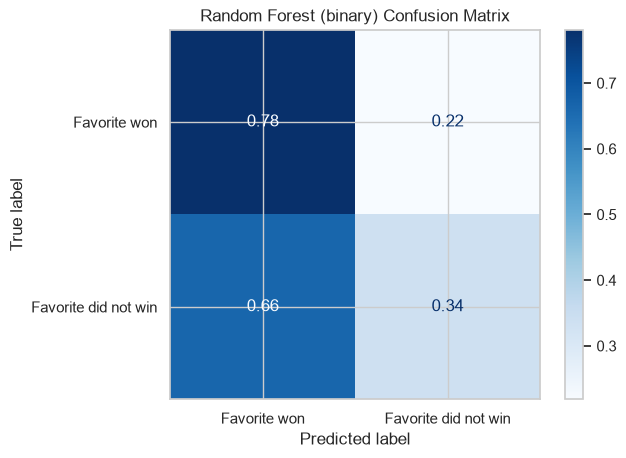

Random Forest train set accuracy : 0.998
Random Forest test set accuracy : 0.614


c:\Users\vyncy\OneDrive\Desktop\MLE_DataMaster\Modulo_Algoritmi_Machine_learning\venv_p12\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)


In [82]:
# define model pipeline
rf_b_pipeline = Pipeline(steps = [('preprocessing', preprocessor_binary), 
                                ('random_forest', RandomForestClassifier(n_estimators = 1000, 
                                                                         random_state = 42, 
                                                                         n_jobs = -1))])

# fit pipeline
rf_b_pipeline.fit(X_train_b, y_train_b)

# extract probability
proba_rf_b = rf_b_pipeline.predict_proba(X_test_b)

# model evaluation
results_binary.append(evaluate_model('Random Forest (binary)', y_test_b, proba_rf_b, class_names_binary))

# check model overfitting
print(f'Random Forest train set accuracy : {rf_b_pipeline.score(X_train_b, y_train_b):.3f}')
print(f'Random Forest test set accuracy : {rf_b_pipeline.score(X_test_b, y_test_b):.3f}')
# test set accuracy << train set accuravy --> model overfits

In [83]:
# Tuning Random Forest hyper-parameters

# define params
param_grid = {'random_forest__n_estimators' : [100, 200, 300], 
              'random_forest__max_depth' : [5, 10, 15, 20], 
              'random_forest__min_samples_leaf' : [1 , 5, 10]}

# define grid search object
grid_search_rf_b = GridSearchCV(estimator = rf_b_pipeline, 
                           param_grid = param_grid, 
                           cv = 5, 
                           scoring = 'f1_macro', 
                           n_jobs = 1)
# fit grid search
grid_search_rf_b.fit(X_train_b, y_train_b)

print(f'Best parameter : {grid_search_rf_b.best_params_}')
print(f'Best cross-validated F1 macro : {grid_search_rf_b.best_score_:.4f}')

c:\Users\vyncy\OneDrive\Desktop\MLE_DataMaster\Modulo_Algoritmi_Machine_learning\venv_p12\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)
c:\Users\vyncy\OneDrive\Desktop\MLE_DataMaster\Modulo_Algoritmi_Machine_learning\venv_p12\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)
c:\Users\vyncy\OneDrive\Desktop\MLE_DataMaster\Modulo_Algoritmi_Machine_learning\venv_p12\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)
c:\Users\vyncy\OneDrive\Desktop\ML

Best parameter : {'random_forest__max_depth': 20, 'random_forest__min_samples_leaf': 1, 'random_forest__n_estimators': 100}
Best cross-validated F1 macro : 0.5615


Random Forest tuned train set accuracy : 0.957
Random Forest tuned test set accuracy : 0.623
====== Random Forest Tuned (binary) performaces ======

F1 values : [0.7287395  0.38255547]
Macro F1 : 0.56
Weighted F1 : 0.60
Log loss: 0.6280
                      precision    recall  f1-score   support

        Favorite won       0.66      0.81      0.73      1335
Favorite did not win       0.50      0.31      0.38       806

            accuracy                           0.62      2141
           macro avg       0.58      0.56      0.56      2141
        weighted avg       0.60      0.62      0.60      2141



c:\Users\vyncy\OneDrive\Desktop\MLE_DataMaster\Modulo_Algoritmi_Machine_learning\venv_p12\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)
c:\Users\vyncy\OneDrive\Desktop\MLE_DataMaster\Modulo_Algoritmi_Machine_learning\venv_p12\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)


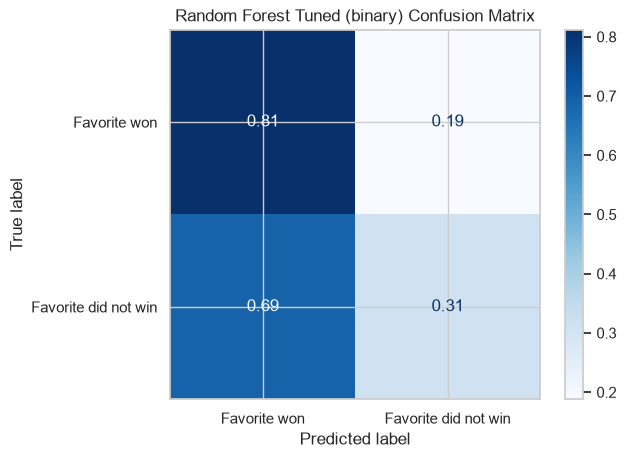

In [84]:
# Random Forest tuned
rf_b_tuned = grid_search_rf_b.best_estimator_

proba_rf_b_tuned = rf_b_tuned.predict_proba(X_test_b)

# check model overfitting
print(f'Random Forest tuned train set accuracy : {rf_b_tuned.score(X_train_b, y_train_b):.3f}')
print(f'Random Forest tuned test set accuracy : {rf_b_tuned.score(X_test_b, y_test_b):.3f}')
# test accuracy < train accuracy but Log-Loss has decreased

# model evaluation
results_binary.append(evaluate_model('Random Forest Tuned (binary)', y_test_b, proba_rf_b_tuned, class_names_binary))

#### XGB

c:\Users\vyncy\OneDrive\Desktop\MLE_DataMaster\Modulo_Algoritmi_Machine_learning\venv_p12\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)


====== XGB (binary) performaces ======

F1 values : [0.71443551 0.42505278]
Macro F1 : 0.57
Weighted F1 : 0.61
Log loss: 0.6704
                      precision    recall  f1-score   support

        Favorite won       0.67      0.77      0.71      1335
Favorite did not win       0.49      0.37      0.43       806

            accuracy                           0.62      2141
           macro avg       0.58      0.57      0.57      2141
        weighted avg       0.60      0.62      0.61      2141



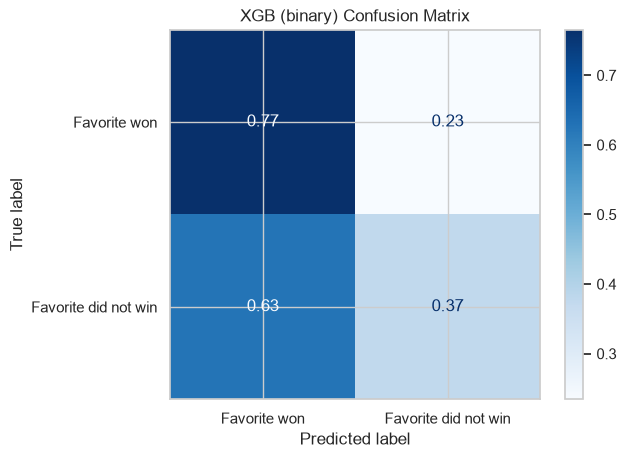

In [85]:
# define model pipeline
xgb_b_pipeline = Pipeline(steps = [('preprocessing', preprocessor_binary), 
                                ('xgb', XGBClassifier(n_estimators = 100, 
                                                      objective = 'binary:logistic', 
                                                      eval_metric = 'logloss',
                                                      random_state = 42))])

# fit pipeline
xgb_b_pipeline.fit(X_train_b, y_train_b)

# extract probability
proba_xgb_b = xgb_b_pipeline.predict_proba(X_test_b)

# model evaluation
results_binary.append(evaluate_model('XGB (binary)', y_test_b, proba_xgb_b, class_names_binary))

In [86]:
# Tuning XGB hyper-parameters

# define params
param_grid = {'xgb__n_estimators' : [100, 200, 300], 
              'xgb__learning_rate' : [0.01, 0.1, 0.3], 
              'xgb__max_depth' : [3, 6, 9]}

# define grid search object
grid_search_xgb_b = GridSearchCV(estimator = xgb_b_pipeline, 
                           param_grid = param_grid, 
                           cv = 5, 
                           scoring = 'f1_macro', 
                           n_jobs = -1)
# fit grid search
grid_search_xgb_b.fit(X_train_b, y_train_b)

print(f'Best parameter : {grid_search_xgb_b.best_params_}')
print(f'Best cross-validated F1 macro : {grid_search_xgb_b.best_score_:.4f}')

Best parameter : {'xgb__learning_rate': 0.3, 'xgb__max_depth': 9, 'xgb__n_estimators': 300}
Best cross-validated F1 macro : 0.5759


XGB tuned train set accuracy : 0.997
XGB tuned test set accuracy : 0.608
====== XGB Tuned (binary) performaces ======

F1 values : [0.69849246 0.43850267]
Macro F1 : 0.57
Weighted F1 : 0.60
Log loss: 0.8678
                      precision    recall  f1-score   support

        Favorite won       0.67      0.73      0.70      1335
Favorite did not win       0.48      0.41      0.44       806

            accuracy                           0.61      2141
           macro avg       0.57      0.57      0.57      2141
        weighted avg       0.60      0.61      0.60      2141



c:\Users\vyncy\OneDrive\Desktop\MLE_DataMaster\Modulo_Algoritmi_Machine_learning\venv_p12\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)
c:\Users\vyncy\OneDrive\Desktop\MLE_DataMaster\Modulo_Algoritmi_Machine_learning\venv_p12\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)


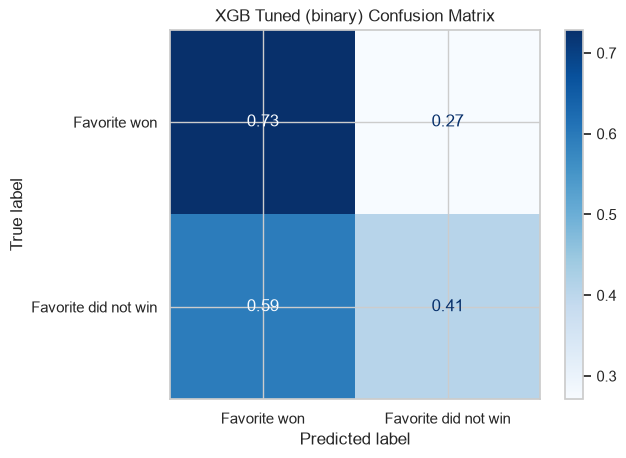

In [87]:
# XGB tuned

xgb_b_tuned = grid_search_xgb_b.best_estimator_

proba_xgb_b_tuned = xgb_b_tuned.predict_proba(X_test_b)

# check model overfitting
print(f'XGB tuned train set accuracy : {xgb_b_tuned.score(X_train_b, y_train_b):.3f}')
print(f'XGB tuned test set accuracy : {xgb_b_tuned.score(X_test_b, y_test_b):.3f}')
# test accuracy < train accuracy but Log-Loss has decreased

# model evaluation
results_binary.append(evaluate_model('XGB Tuned (binary)', y_test_b, proba_xgb_b_tuned, class_names_binary))

In [88]:
Comparison_binary = pd.DataFrame(results_binary)
Comparison_binary

,Model,Accuracy,F1_Favorite won,F1_Favorite did not win,F1_macro,F1_weighted,Log_Loss
0,Dummy (binary),0.623540,0.768124,0.000000,0.384062,0.478957,0.662304
1,Logistic_Regression (binary),0.623073,0.767636,0.002472,0.385054,0.479583,0.666996
2,Logistic_Regression_balanced (binary),0.502102,0.536118,0.462702,0.499410,0.508480,0.698472
3,Random Forest (binary),0.613732,0.716100,0.395909,0.556005,0.595561,0.637560
4,Random Forest Tuned (binary),0.623073,0.728739,0.382555,0.555647,0.598415,0.628000
5,XGB (binary),0.618403,0.714436,0.425053,0.569744,0.605495,0.670428
6,XGB Tuned (binary),0.607660,0.698492,0.438503,0.568498,0.600617,0.867819


### 3.3 Threshold analysis

In [89]:
# XGBoost base line has the relatively better performance (recall, F1 -favorite did not win class-) so,
# try diffente value of threshold  lower trhesholds to raise recall

proba_positive = 1  # index of 'favorite_not_win' in predict_proba output, verify with model.classes_

y_proba_xgb = xgb_b_pipeline.predict_proba(X_test_b)[:, proba_positive]

thresholds = [0.4, 0.35, 0.3, 0.25]

for t in thresholds:

    y_pred_lower_t = y_proba_xgb >= t

    print(f"====== XGB tuned performances with threshold : {t} ======")
    print(classification_report(y_test_b, y_pred_lower_t, target_names=class_names_binary, zero_division=0))


====== XGB tuned performances with threshold : 0.4 ======
                      precision    recall  f1-score   support

        Favorite won       0.69      0.62      0.66      1335
Favorite did not win       0.47      0.54      0.50       806

            accuracy                           0.59      2141
           macro avg       0.58      0.58      0.58      2141
        weighted avg       0.61      0.59      0.60      2141

====== XGB tuned performances with threshold : 0.35 ======
                      precision    recall  f1-score   support

        Favorite won       0.71      0.53      0.61      1335
Favorite did not win       0.45      0.65      0.53       806

            accuracy                           0.57      2141
           macro avg       0.58      0.59      0.57      2141
        weighted avg       0.62      0.57      0.58      2141

====== XGB tuned performances with threshold : 0.3 ======
                      precision    recall  f1-score   support

        Favo

c:\Users\vyncy\OneDrive\Desktop\MLE_DataMaster\Modulo_Algoritmi_Machine_learning\venv_p12\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)


#### Considerations: 
- base line XGBoost has relatively better performances (recall, F1-score)
- threshold = 0.35 appears to offer a good compromise between the model's recall and precision.

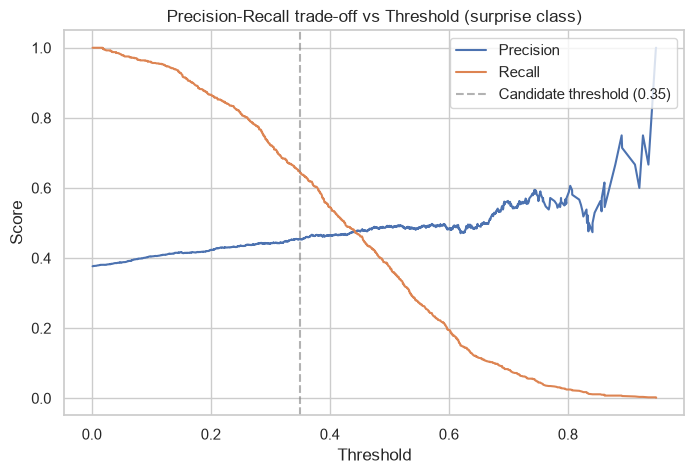

In [90]:
# precision-recall trade-off as a function of threshold, for the 'favorite_not_win' (surprise) class
precision, recall, thresholds_pr = precision_recall_curve(y_test_b, y_proba_xgb)

plt.figure(figsize=(8, 5))
plt.plot(thresholds_pr, precision[:-1], label='Precision')
plt.plot(thresholds_pr, recall[:-1], label='Recall')
plt.axvline(x=0.35, color='gray', linestyle='--', alpha=0.6, label='Candidate threshold (0.35)')
plt.xlabel('Threshold')
plt.ylabel('Score')
plt.title('Precision-Recall trade-off vs Threshold (surprise class)')
plt.legend(loc='upper right')
plt.savefig('images/Precision-Recall.png', dpi = 300, bbox_inches = 'tight')
plt.show()

# 4. Feature Importance/SHAP analysis

### 4.1 Three classes model - Random Forest Tuned

#### Feature Importance

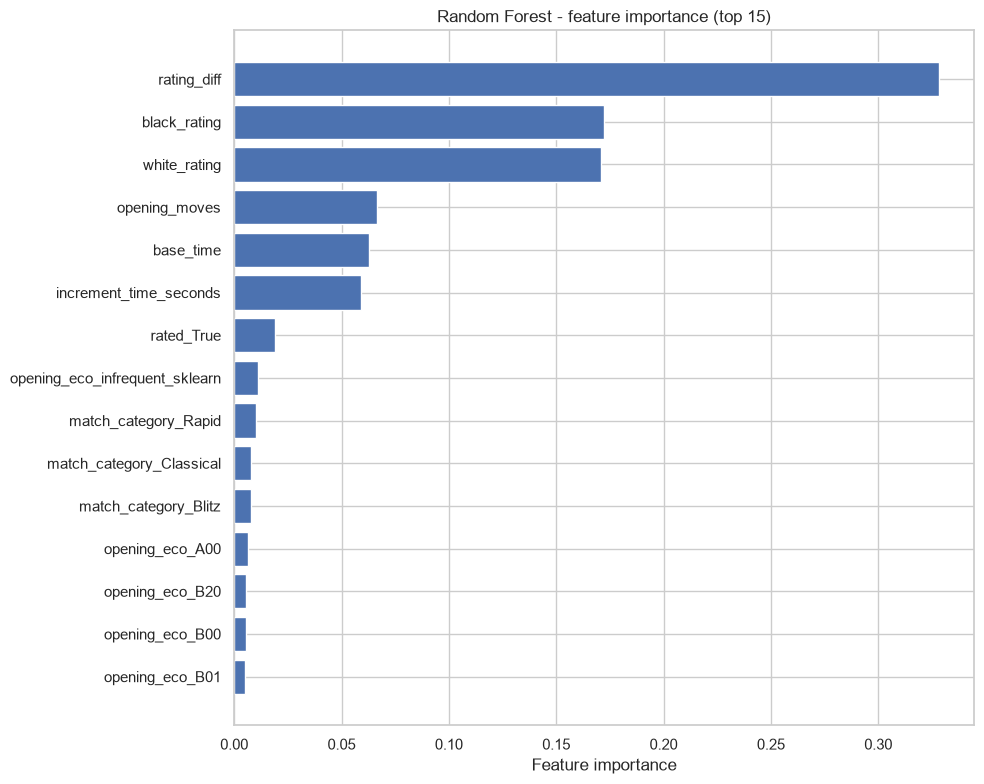

In [91]:
rf_tuned.named_steps.keys()

# extract feature names after preprocessing and the model's native importances
feature_names = rf_tuned.named_steps['preprocessing'].get_feature_names_out()
feature_names_clean_ =np.array([name.replace('num__','') if name.startswith('num__') else name.replace('cat__','') for name in feature_names])
importances = rf_tuned.named_steps['random_forest'].feature_importances_

# sort descending for a readable plot
sorted_idx = np.argsort(importances)[::-1] # reversing vector

plt.figure(figsize = (10,8))
plt.barh(feature_names_clean_ [sorted_idx][:15], importances[sorted_idx][:15])
plt.gca().invert_yaxis()
plt.xlabel('Feature importance')
plt.title('Random Forest - feature importance (top 15)')
plt.tight_layout()
plt.savefig('images/Random_forest_feature_importance.png', dpi = 300, bbox_inches = 'tight')
plt.show()

In [92]:
# aggregate importance of all opening_eco dummy columns into a single value
opening_eco_mask = np.array([name.startswith('opening_eco') for name in feature_names_clean_ ]) # Boolean vector
opening_eco_total = importances[opening_eco_mask].sum()
print(f'Combined opening_eco importance: {opening_eco_total:.3f}')
print(f'Number of opening_eco columns summed: {opening_eco_mask.sum()}')

Combined opening_eco importance: 0.096
Number of opening_eco columns summed: 21


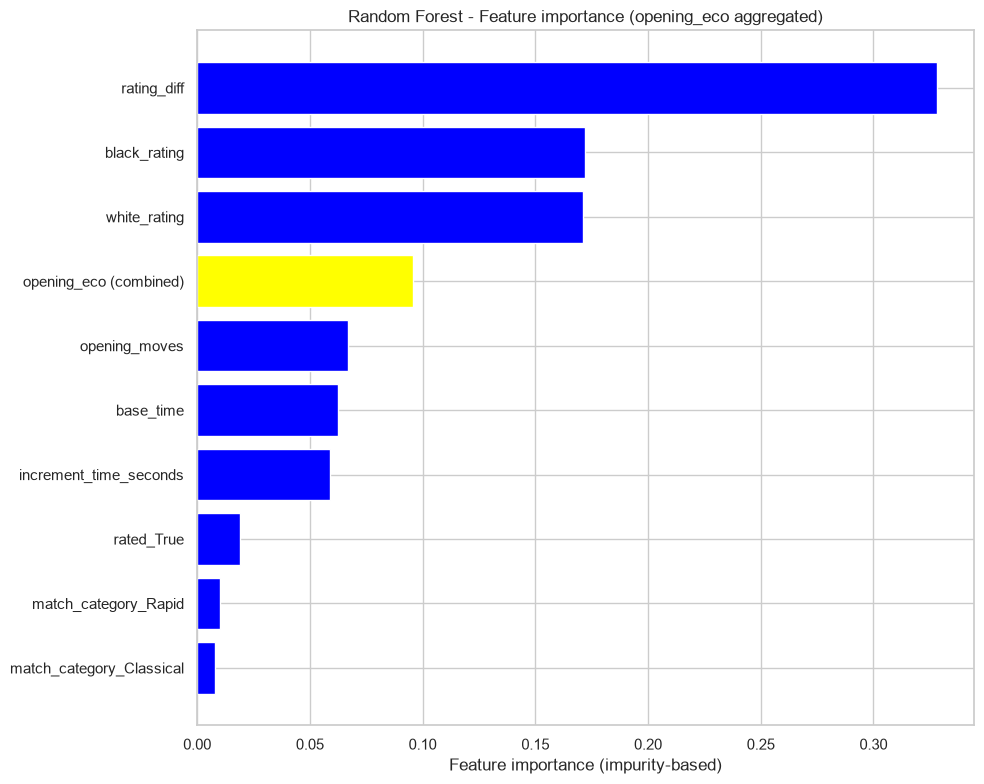

In [93]:
# build an aggregated view: all opening_eco columns collapsed into one bar
agg_names = list(feature_names_clean_ [~opening_eco_mask]) + ['opening_eco (combined)']
agg_importances = list(importances[~opening_eco_mask]) + [opening_eco_total]

agg_names = np.array(agg_names)
agg_importances = np.array(agg_importances)

sorted_idx_agg = np.argsort(agg_importances)[::-1]

# highlight only the aggregated opening_eco bar with a different color
bar_colors = ['blue' if name != 'opening_eco (combined)' else 'yellow' 
              for name in agg_names[sorted_idx_agg][:10]]

plt.figure(figsize=(10, 8))
plt.barh(agg_names[sorted_idx_agg][:10], agg_importances[sorted_idx_agg][:10], color = bar_colors)
plt.gca().invert_yaxis()
plt.xlabel('Feature importance (impurity-based)')
plt.title('Random Forest - Feature importance (opening_eco aggregated)')
plt.tight_layout()
plt.savefig('images/Random_forest_feature_importance_opening_eco_aggregated.png', dpi = 300, bbox_inches = 'tight')
plt.show()

#### SHAP analysis

In [94]:
# TreeExplainer
explainer_rf = shap.TreeExplainer(rf_tuned.named_steps['random_forest'])

# transform test data
X_test_transformed = rf_tuned.named_steps['preprocessing'].transform(X_test)

shap_values_rf = explainer_rf.shap_values(X_test_transformed)

c:\Users\vyncy\OneDrive\Desktop\MLE_DataMaster\Modulo_Algoritmi_Machine_learning\venv_p12\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)


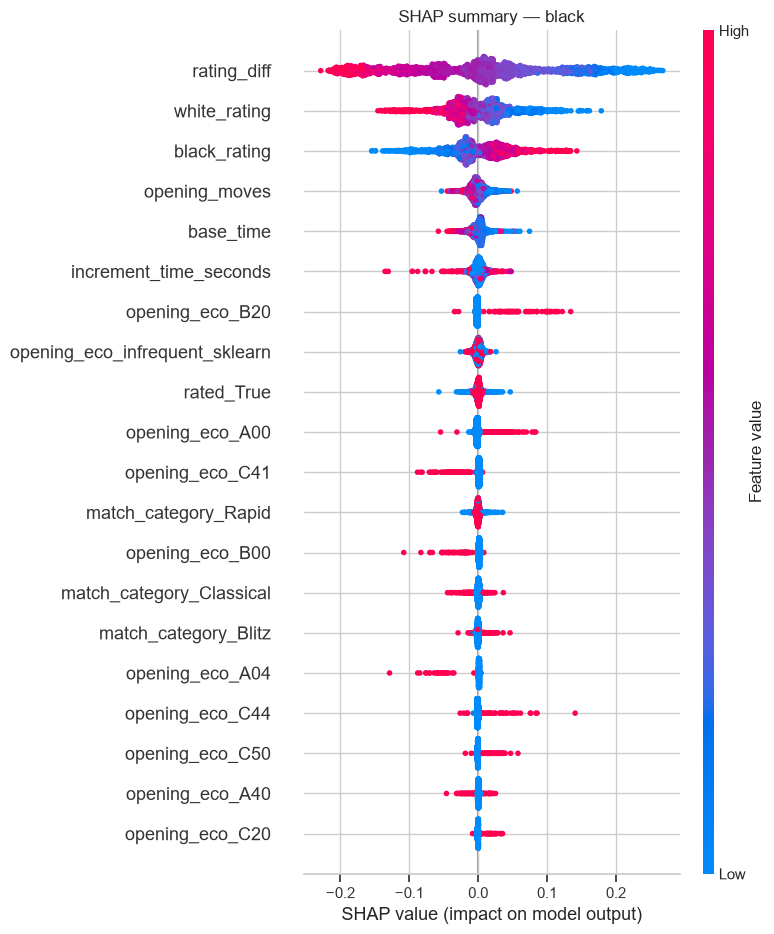

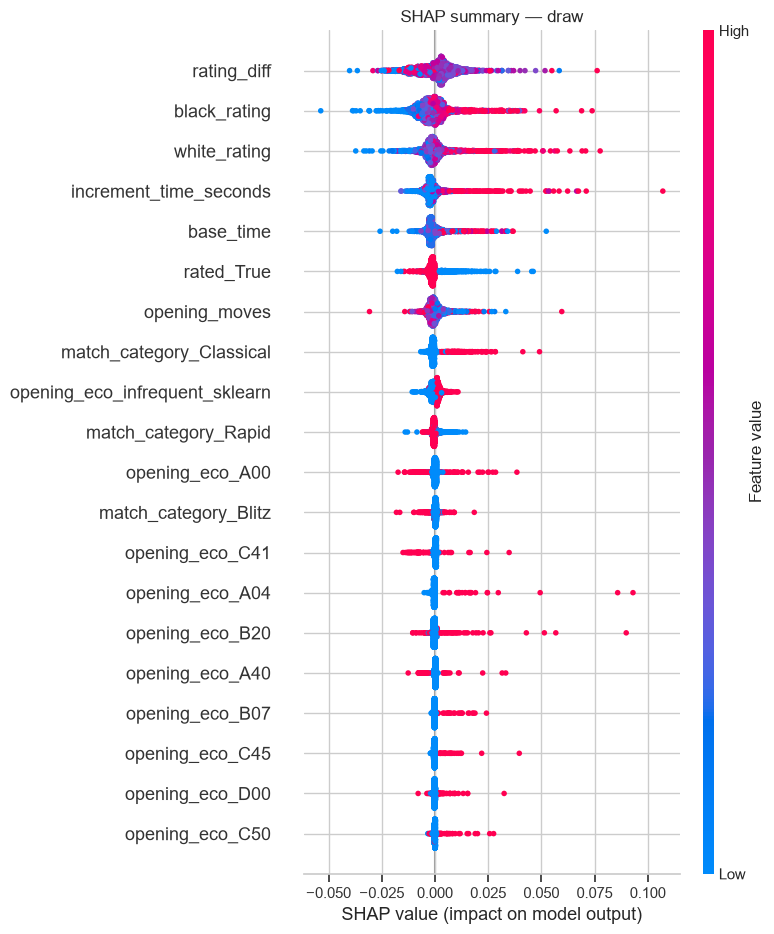

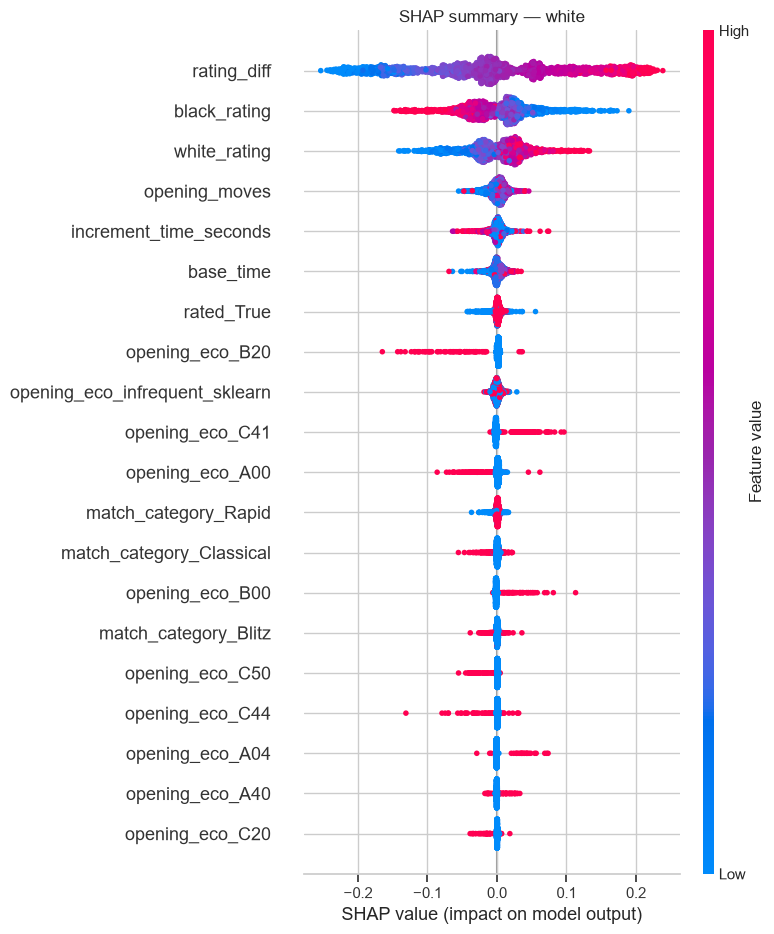

In [95]:
# summary plot: overall feature importance + direction of impact

for i, class_name in enumerate(class_names):
    shap.summary_plot(shap_values_rf[:,:,i], X_test_transformed, feature_names = feature_names_clean_ , class_names = class_name, show = False)
    plt.title(f"SHAP summary — {class_name}")
    plt.tight_layout()
    plt.savefig(f'images/shap_summary_{class_name}_random_forest.png', dpi=300, bbox_inches='tight')
    plt.show()

#### Considerations:
- The behavior of the shape values for the white and black classes is specular
- *rating_diff* has a leading role (specular between blck and white classes)
- opening move *B20* tends to favourite black class prediction
- In draw prediction time base features seem to impact but ther isn't a clear path, while *rated* shows an interesting distribution

### 4.2 Binary classification model - XGBoost

#### Feature Importance

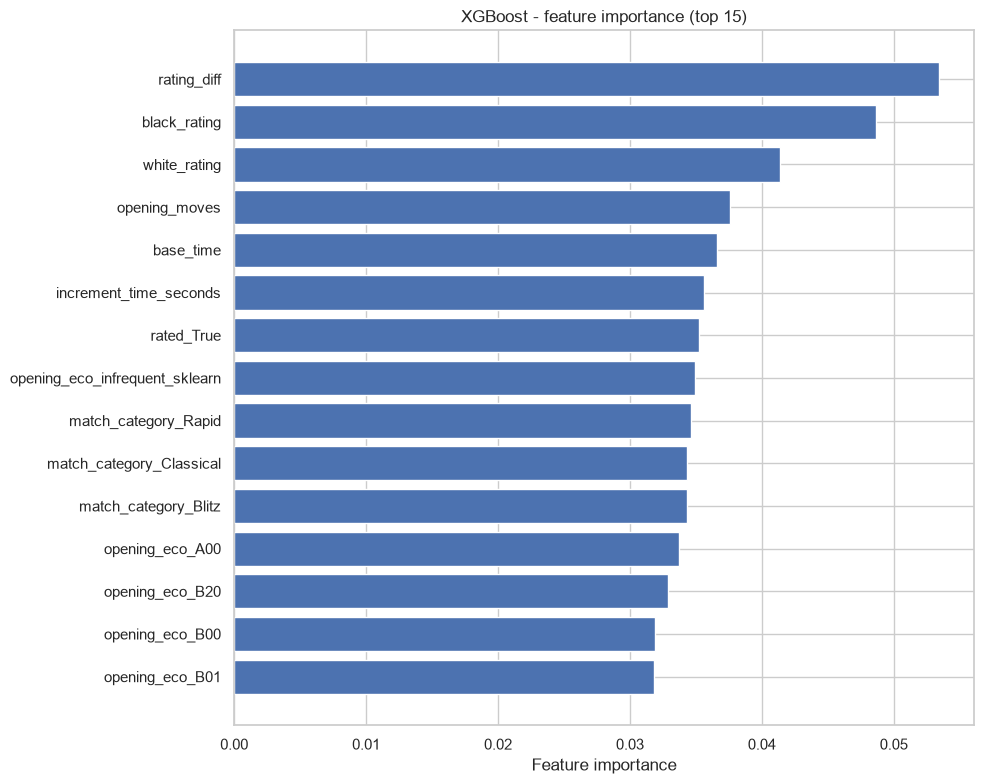

In [96]:
xgb_b_pipeline.named_steps.keys()

# extract feature names after preprocessing and the model's native importances
feature_names_b = xgb_b_pipeline.named_steps['preprocessing'].get_feature_names_out()
feature_names_clean =np.array([name.replace('num__','') if name.startswith('num__') else name.replace('cat__','') for name in feature_names_b])
 
importances_xgb = xgb_b_pipeline.named_steps['xgb'].feature_importances_

# sort descending for a readable plot
sorted_idx_xgb = np.argsort(importances_xgb)[::-1]

plt.figure(figsize = (10,8))
plt.barh(feature_names_clean[sorted_idx][:15], importances_xgb[sorted_idx_xgb][:15])
plt.gca().invert_yaxis()
plt.xlabel('Feature importance')
plt.title('XGBoost - feature importance (top 15)')
plt.tight_layout()
plt.savefig('images/xgb_importance.png', dpi = 300, bbox_inches = 'tight')
plt.show()

In [97]:
# aggregate importance of all opening_eco dummy columns into a single value
opening_eco_mask_xgb = np.array([name.startswith('opening_eco') for name in feature_names_clean]) # Boolean vector
opening_eco_total_xgb = importances_xgb[opening_eco_mask_xgb].sum()
print(f'Combined opening_eco importance: {opening_eco_total_xgb:.3f}')
print(f'Number of opening_eco columns summed: {opening_eco_mask_xgb.sum()}')

Combined opening_eco importance: 0.672
Number of opening_eco columns summed: 21


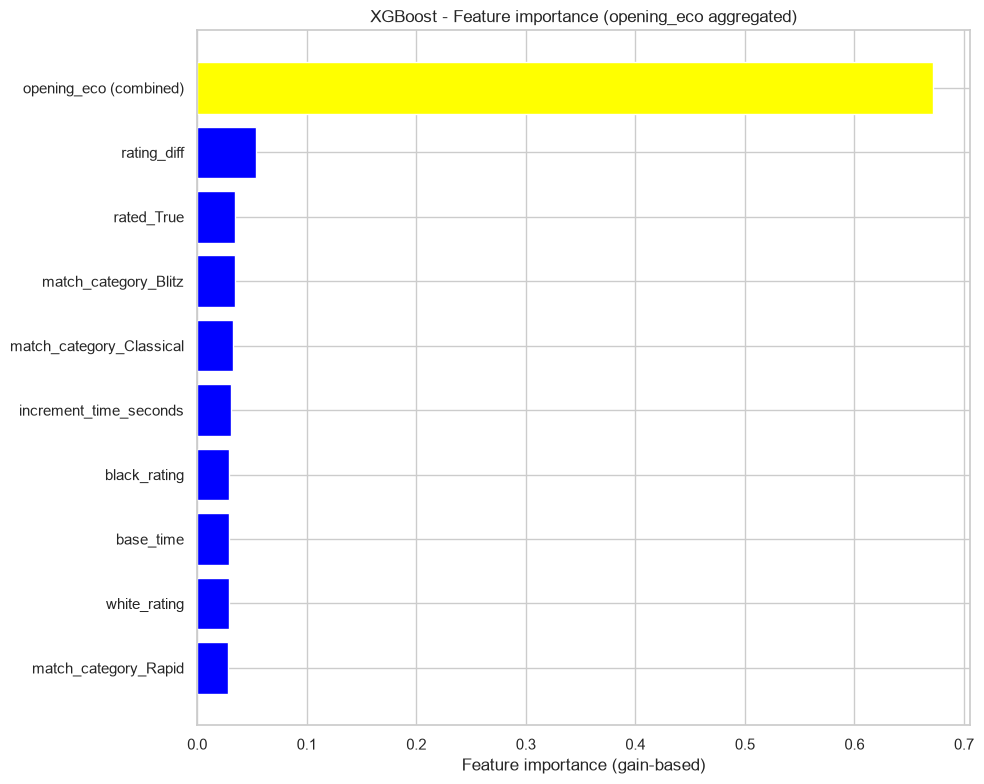

In [98]:
# build an aggregated view: all opening_eco columns collapsed into one bar
agg_names_xgb = list(feature_names_clean[~opening_eco_mask_xgb]) + ['opening_eco (combined)']
agg_importances_xgb = list(importances_xgb[~opening_eco_mask_xgb]) + [opening_eco_total_xgb]

agg_names_xgb = np.array(agg_names_xgb)
agg_importances_xgb = np.array(agg_importances_xgb)

sorted_idx_agg_xgb = np.argsort(agg_importances_xgb)[::-1]

# highlight only the aggregated opening_eco bar with a different color
bar_colors = ['blue' if name != 'opening_eco (combined)' else 'yellow' 
              for name in agg_names_xgb[sorted_idx_agg_xgb][:10]]

plt.figure(figsize=(10, 8))
plt.barh(agg_names_xgb[sorted_idx_agg_xgb][:10], agg_importances_xgb[sorted_idx_agg_xgb][:10], color = bar_colors)
plt.gca().invert_yaxis()
plt.xlabel('Feature importance (gain-based)')
plt.title('XGBoost - Feature importance (opening_eco aggregated)')
plt.tight_layout()
plt.savefig('images/xgb_feature_importance_opening_eco_aggregated.png', dpi = 300, bbox_inches = 'tight')
plt.show()

#### SHAP analysis

In [99]:
explainer_xgb = shap.TreeExplainer(xgb_b_pipeline.named_steps['xgb'])  # verify exact step name

X_test_b_transformed = xgb_b_pipeline.named_steps['preprocessing'].transform(X_test_b)

shap_values_xgb = explainer_xgb.shap_values(X_test_b_transformed)

#print(type(shap_values_xgb_b))
#(shap_values_xgb_b.shape if hasattr(shap_values_xgb_b, 'shape') else len(shap_values_xgb_b))

c:\Users\vyncy\OneDrive\Desktop\MLE_DataMaster\Modulo_Algoritmi_Machine_learning\venv_p12\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)


In [100]:
print(type(shap_values_xgb))
print(shap_values_xgb.shape if hasattr(shap_values_xgb, 'shape') else len(shap_values_xgb))

<class 'numpy.ndarray'>
(2141, 31)


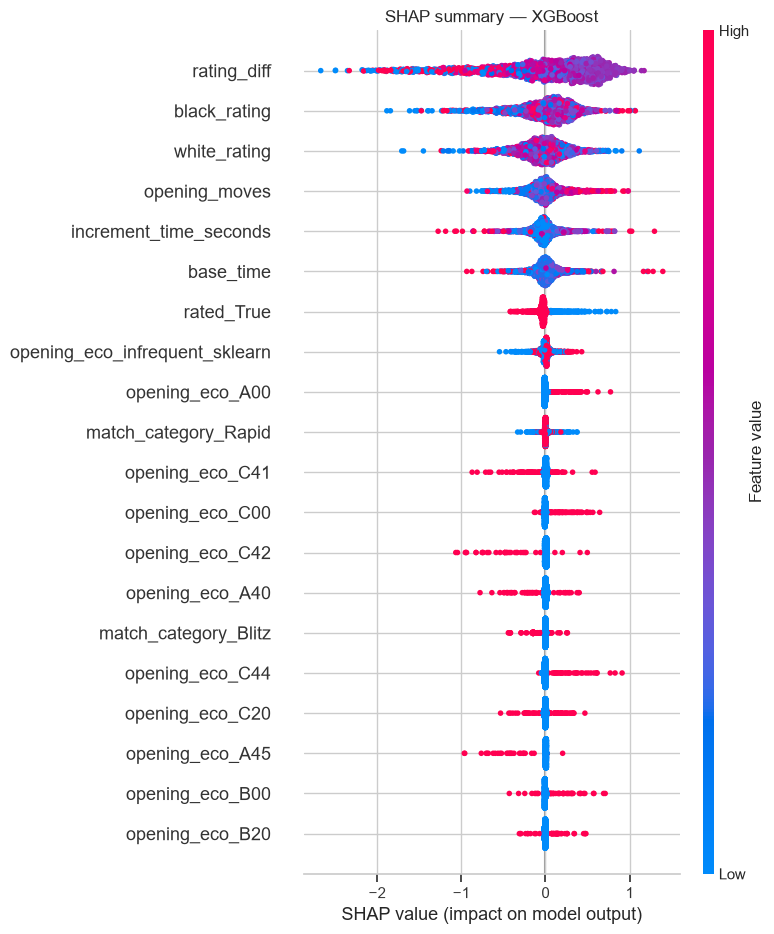

In [101]:
# summary plot: overall feature importance + direction of impact

shap.summary_plot(shap_values_xgb, X_test_b_transformed, feature_names = feature_names_clean, show = False)
plt.title("SHAP summary — XGBoost")
plt.tight_layout()
plt.savefig(f'images/shap_summary_xgb.png', dpi=300, bbox_inches='tight')
plt.show()

#### Considerations:
- *rating_diff* has a leading role but more noisy here
- *opening_moves* has a clear path
- *rated* confirms EDA analysis, casual matches (rated == False) relate to surprire outcomes
- some indivial openings seem to show a clear path (A00, C00..)
- consider that x-axe calculates as log-odds

# 5. Serialization & Inference function

#### Three Classes prediction serialization

In [102]:
models_dir = Path('models')
models_dir.mkdir(parents = True, exist_ok = True)

In [103]:
# save model + label encoder
joblib.dump(rf_tuned, models_dir / 'three_classification_model.pkl')
joblib.dump(le, models_dir / 'label_encoder_three_classification_model.pkl')

['models\\label_encoder_three_classification_model.pkl']

#### Binary prediction serialization

In [104]:
# save binary model
joblib.dump(xgb_b_pipeline, models_dir / 'binary_model.pkl')
#joblib.dump(0.35, models_dir / 'binary_threshold.pkl')

# save choosed threshold + other parameters as json file
config_params = {
    'binary_threshold' : 0.35,
    'three_class_names' : list(class_names), # TypeError: Object of type ndarray is not JSON serializable
    'binary_class_names' : ['Favorite won', 'Favorite did not win']
}

with open (models_dir / 'config_params.json', 'w') as f:
    json.dump(config_params, f, indent = 2)

In [105]:
# check file integrity

loaded_model = joblib.load(models_dir / 'three_classification_model.pkl')

In [106]:
original_proba = rf_tuned.predict_proba(X_test)
loaded_proba = loaded_model.predict_proba(X_test)

print(np.allclose(original_proba, loaded_proba))

True


c:\Users\vyncy\OneDrive\Desktop\MLE_DataMaster\Modulo_Algoritmi_Machine_learning\venv_p12\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)
c:\Users\vyncy\OneDrive\Desktop\MLE_DataMaster\Modulo_Algoritmi_Machine_learning\venv_p12\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)


#### Inference function

In [ ]:
def predict_match_outcome(match_data, three_class_pipeline, label_encoder, 
                           binary_pipeline, binary_threshold):
    
    """
    Predict the outcome of one or more chess matches, using only
    pre-match (or early-move) information.

    match_data: a single dict, or a list of dicts, each with keys:
                'white_rating', 'black_rating', 'increment_code',
                'opening_eco', 'opening_ply', 'rated' (bool)

    Returns a DataFrame with one row per match: predicted probabilities
    for black/draw/white, the surprise probability, and the matchmaking flag.
    """
    
    # function accepts either a single match (dict) or a batch (list of dicts)
    if isinstance(match_data, dict):
        match_data = [match_data]

    df = pd.DataFrame(match_data)

    # feature engineering: must exactly replicate what was done in the notebook

    # NOTE: the raw dataset uses 'opening_ply'; the pipeline was trained on 'opening_moves'
    df = df.rename(columns={'opening_ply': 'opening_moves'})

    df['rating_diff'] = df['white_rating'] - df['black_rating']

    # split increment_code (e.g. "10+0") into base time and increment, in seconds
    split_time = df['increment_code'].str.split('+', expand=True)
    df['base_time'] = split_time[0].astype(int)
    df['increment_time_seconds'] = split_time[1].astype(int)

    # estimate a "typical" game duration to classify the time control (Bullet/Blitz/Rapid/Classical)
    df['estimated_minutes'] = df['base_time'] + (df['increment_time_seconds'] * 40 / 60)
    df['match_category'] = df['estimated_minutes'].apply(categorize_time)  # reuse the notebook's function


    # data quality check: flag opening_eco values unseen during training
    # retrieve the learned categories directly from the fitted OneHotEncoder inside the pipeline

    cat_pipeline_fitted = three_class_pipeline.named_steps['preprocessing'].named_transformers_['cat']
    cat_encoder = cat_pipeline_fitted.named_steps['encoder']  # one more step down, to the actual OneHotEncoder

    opening_eco_position = list(cat_encoder.feature_names_in_).index('opening_eco')
    known_openings = set(cat_encoder.categories_[opening_eco_position])

    df['opening_eco_unknown'] = ~df['opening_eco'].isin(known_openings)

    if df['opening_eco_unknown'].any():
        n_unknown = df['opening_eco_unknown'].sum()
        print(f"Warning: {n_unknown} match(es) have an opening_eco value not seen during training "
              f"(treated as 'infrequent' by the model). This may indicate a data entry error "
              f"or genuine drift in opening popularity — worth monitoring over time.")

    # three-class model: predict black / draw / white probabilities
    proba_3class = three_class_pipeline.predict_proba(df)
    prediction_results = pd.DataFrame(proba_3class, columns=[f'proba_{c}' for c in label_encoder.classes_])

    # binary model: predict whether the favorite does NOT win (matchmaking use case)
    proba_binary = binary_pipeline.predict_proba(df)[:, 1]
    prediction_results['surprise_probability'] = proba_binary
    prediction_results['flagged_as_potential_surprise'] = proba_binary >= binary_threshold


 

In [ ]:
match = [{
    'white_rating': 1600, 'black_rating': 1450, 'increment_code': '10+0',
    'opening_eco': 'B20', 'opening_ply': 4, 'rated': True
}, 
         {
    'white_rating': 600, 'black_rating': 1450, 'increment_code': '10+10',
    'opening_eco': 'AOO', 'opening_ply': 10, 'rated': False
         }
        ]

prediction = predict_match_outcome(match, rf_tuned, le, xgb_b_pipeline, 0.35)

In [109]:
prediction

,proba_black,proba_draw,proba_white,surprise_probability,flagged_as_potential_surprise,opening_eco_unknown
0,0.529120,0.046211,0.424669,0.380109,True,False
1,0.691175,0.027960,0.280864,0.053633,False,True


In [ ]:
# test inference module function
from inference import predict_match_outcome

In [9]:
prediction = predict_match_outcome(match)
# save prediction for test_inference.py
prediction.to_csv('tests/expected_predictions.csv', index=False)
print(prediction)


   proba_black  proba_draw  proba_white  surprise_probability  \
0     0.529120    0.046211     0.424669              0.380109   
1     0.691175    0.027960     0.280864              0.053633   

   flagged_as_potential_surprise  opening_eco_unknown  
0                           True                False  
1                          False                 True  


C:\Users\vyncy\AppData\Local\Temp\ipykernel_26612\3667481865.py:1: UserWarning: 1 match(es) have an opening_eco value not seen during training (treated as 'infrequent' by the model). This may indicate a data entry error or genuine drift in opening popularity - worth monitoring over time.
  prediction = predict_match_outcome(match)
c:\Users\vyncy\OneDrive\Desktop\MLE_DataMaster\Modulo_Algoritmi_Machine_learning\venv_p12\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)
c:\Users\vyncy\OneDrive\Desktop\MLE_DataMaster\Modulo_Algoritmi_Machine_learning\venv_p12\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)


In [15]:
not (prediction.iloc[0] == prediction.iloc[1]).any()

True